# Problem framing

**Objective**

---

In this notebook we aim to develop a pipeline for total veins vessel length prediction from incomplete images of bat wings. The pipeline will be used for automating measurements in an ongoing research study on bat heat diffusion.

The current measurement methodology is manual and labor intensive. We aim to have comparable accuracy and be extremely time efficient.

**System design**

---

The requirements for this task break down as: semantic segmentation followed by skeletonization and finally metric conversion.
For this purpose, we expect to build a single end to end pipeline that performs the following steps:
- Preprocess images and masks
- Predict a mask for each image
- Postprocess masks
- Estimate pixel length of vein mask class
- Convert pixel length to milimeters

**Performance measure**


---

We will measure performance by comparing predicted vessels length to the manually annotated ones. Our objective is to achieve an average error lower or equal to ±2.5% (from the median of manually annotated labels) with a low but no yet defined std. Our segmentation model will probably use a loss function centered around high similarity and connectivity masks like clDice.

**Assumptions**

---

...

# Data information

**Data description**

---

This project dataset contains camera images of bat specimens curated to study wing vasculature. Source photos were tiled into fixed-size patches (uniform resolution and PNG format) and organized by specimen. Each tile is manually annotated in CVAT with a binary semantic mask of vessels. In addition to the mask, labels include total visible vessel length and vessel width measurements per tile. Tiles may be show no vessels whatsoever (background) or show anatomical regions (notably wings), where vessel structures are of interest.

For each specimen, the mentioned dataset usually contains < 1k tile photos, from which a noticeable amount dont contain vessels. Empty masks do exist for these background tiles.

**Data sampling**

---

Specimens were captured and photographed with a camera following this protocol:
- Center the light focus on the wing.
- Use two lights and a paper diffuser.
- Avoid placing tape on the wing.
- Uropatagium: keep it well extended; note that its venation is not bilaterally symmetrical.
- As background use a 5x5mm grid.

**Data issues**

---

- A small fraction of masks are empty when they shouldnt due to annotation errors.
- Images may contain small perturbations such as silhouettes from bugs, etc...

# Tracking & versioning utility

In [1]:
!pip install skorch
!pip install imagehash
!pip install pybktree
!pip install skan
!pip install segmentation-models-pytorch

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pybktree: filename=pybktree-1.1-py3-none-any.whl size=5025 sha256=d4891d346906dcdf40cc9da6a0d1c9ad173e69d8cce16a082e16625ce16cba98
  Stored in directory: /root/.cache/pip/wheels/d9/f0/dd/545edc6df9148221657c15a0c0a42ec00b216c8c9d42d559e9
Successfully built pybktree
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 54.4 MB/s  0:00:00


In [ ]:
import wandb
import os
from google.colab import userdata, files

wandb.Table.MAX_ARTIFACT_ROWS = 1_000_000
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

#wandb.login(key=userdata.get("wandb_api"))
api = wandb.Api()

for dir_name in ["data", "models", "pipelines", "transformers", "misc"]:
  os.makedirs(dir_name, exist_ok=True)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dimi3 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [3]:
# Useful commands for Google Colab
#!unzip /content/Phyl_disc_dataset.zip -d /content/my_data
#!ls -la

In [4]:
from skimage.morphology import skeletonize, remove_small_holes, remove_small_objects
from scipy.ndimage import distance_transform_edt
from skan import Skeleton, summarize
import numpy as np
import pandas as pd

def estimate_vein_stats(mask: np.ndarray, px_mm_ratio:float) -> dict:

    mask = remove_small_holes(mask.astype(bool), area_threshold=3)
    mask = remove_small_objects(mask, min_size=5)
    skeleton = skeletonize(mask)
    
    if np.sum(skeleton) <= 1: return {} # NOTE: Condition update to include 1, starting from raw ds v2 onward

    radius_map = distance_transform_edt(mask)
    
    skeleton_radii = radius_map[skeleton]
    px_avg_width = 2.0 * np.mean(skeleton_radii)
    mm_avg_width = px_avg_width * px_mm_ratio

    px_area = np.sum(mask)
    mm2_area = px_area * (px_mm_ratio ** 2)
    
    skel_obj = Skeleton(skeleton)
    branch_df = summarize(skel_obj, separator="-")
    
    total_px_length = branch_df["branch-distance"].sum()
    junction_indices = np.where(skel_obj.degrees > 2)[0]
    total_px_correction = 0.0
    
    for node_idx in junction_indices:

        y, x = skel_obj.coordinates[node_idx].astype(int)
        radius = radius_map[y, x]
        degree = skel_obj.degrees[node_idx]
        correction = (degree - 2) * radius
        total_px_correction += correction

    corrected_px_length = max(0, total_px_length - total_px_correction)
    total_mm_length = corrected_px_length * px_mm_ratio
    
    return {
        "mm_length": total_mm_length,
        "px_length": total_px_length,
        "px_correction": total_px_correction,
        "junction_count": len(junction_indices),
        "percent_reduction": (total_px_correction / total_px_length) * 100,
        "px_avg_width": float(px_avg_width),
        "mm_avg_width": float(mm_avg_width),
        "px_area": int(px_area),
        "mm2_area": float(mm2_area)
    }

In [5]:
from PIL import Image

def generate_measurements(root_dir):

    mask_dir = os.path.join(root_dir, "mask", "raw")
    measurements_path = os.path.join(root_dir, "measurements.csv")
    measurements = pd.read_csv(measurements_path)

    results = {"filename": [], "length_mm": [], "width_mm": [], "area_mm2": []}
    
    for filename in sorted(os.listdir(mask_dir)):
            
        mask_path = os.path.join(mask_dir, filename)
        mask = np.array(Image.open(mask_path).convert("L"))
        stats = estimate_vein_stats(mask, 0.071)
        
        results["filename"].append(filename)
        results["length_mm"].append(stats.get("mm_length", 0.0))
        results["width_mm"].append(stats.get("mm_avg_width", 0.0))
        results["area_mm2"].append(stats.get("mm2_area", 0.0))

    new_measurements = pd.merge(measurements, pd.DataFrame(results), on="filename", how="left")
    #measurements.update(pd.DataFrame(results))
    #measurements.to_csv(measurements_path, index=False)
    new_measurements.to_csv(measurements_path, index=False)

In [6]:
print("keep going")

keep going


In [7]:
# from pathlib import Path

# # Iterate through files and folders in the current directory
# for item in Path('Phyl_disc').iterdir():
#     if item.is_file():
#         print(f"File:   {item.name}")
#     elif item.is_dir():
#         print(f"Folder: {item.name}")

In [8]:
# generate_measurements("Phyl_disc")

In [9]:
import torch
from torch.utils.data import Dataset
import pandas as pd
import numpy as np
from PIL import Image
import os
from typing import Union

class BatVeinDataset(Dataset):
    def __init__(
            self,
            root_dir: Union[str, os.PathLike],
            measurements: pd.DataFrame = None,
            transform: any = None,
            train_mode: bool = False
            ) -> None:
        """
        root_dir: Path containing /images, /masks, and measurements.csv
        measurements: Optional pre-loaded DataFrame of measurements
        transform: Albumentations or Torchvision transforms
        """
        self.root_dir = root_dir
        self.transform = transform
        self.train_mode = train_mode
        if measurements is not None: self.measurements = measurements
        else: self.measurements = pd.read_csv(os.path.join(root_dir, "measurements.csv"))
        self.measurements.set_index("filename", inplace=True)

    def __len__(self):
        return len(self.measurements)

    def __getitem__(self, idx):

        filename = self.measurements.index[idx]

        img_path = os.path.join(self.root_dir, "source", filename)
        raw_mask_path = os.path.join(self.root_dir, "mask", "raw", filename)
        color_mask_path = os.path.join(self.root_dir, "mask", "colorized", filename)

        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(raw_mask_path).convert("L"))
        mask_color = np.array(Image.open(color_mask_path).convert("RGB"))

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image_tensor = augmented["image"]
            mask_tensor = (augmented["mask"].unsqueeze(0) > 0).float()
        else:
            image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
            mask_tensor = (torch.from_numpy(mask).unsqueeze(0) > 0).float()

        output = {
            "image_tensor": image_tensor, # Shape: (3, H, W)
            "mask_tensor": mask_tensor, # Shape: (1, H, W)
            "measurements": self.measurements.iloc[idx].to_dict(),
            "id": filename
        }

        if not self.train_mode: output["image"] = image; output["mask"] = mask; output["mask_color"] = mask_color

        return output


In [10]:
from datetime import datetime
from hashlib import md5
from enum import Enum
from pathlib import Path
import albumentations as A
import json
import hashlib

class DatasetKind(Enum):
  RAW = "raw"
  TRAIN = "train"
  TEST = "test"

def version_manifest(manifest:pd.DataFrame, kind:DatasetKind, transforms: A.Compose = None) -> None:
  data_name = f"{kind.value}-set"
  title = input("Commit title: ")
  message = input("Commit message: ")
  alias = input("Version alias (blank for 'latest' only): ")
  deps = []
  while True:
    dep = input("Data dependency (blank to finish): ")
    if not dep: break
    deps.append("dimi3/Vein Length Estimator/" + dep)

  if transforms is not None:
    transforms = transforms.to_dict()
    serialized_transforms = json.dumps(transforms, sort_keys=True)
    manifest = manifest.copy()
    manifest["transforms_hash"] = hashlib.md5(serialized_transforms.encode("utf-8")).hexdigest()[:8]

  version = f"v{datetime.now().strftime('%Y%m%d_%H%M%S')}"
  metadata = {
      "n_images": len(manifest),
      "measurements": list(manifest.columns),
      "transforms": transforms
  }
  if kind == DatasetKind.TRAIN: metadata["n_folds"] = len(manifest["val_fold"].unique())
  run = wandb.init(
      project="Vein Length Estimator",
      job_type="versioning",
      name=title,
      notes=message,
      tags=["data"],
      save_code=True
  )
  for dep in deps: run.use_artifact(dep, type="dataset")
  artifact = wandb.Artifact(
      name=data_name,
      type="manifest",
      description=f"Version {version} of {data_name}",
      metadata=metadata,
  )
  manifest_path = f"data/{data_name + version}-manifest.csv"
  manifest.to_csv(manifest_path)
  artifact.add_file(manifest_path, "manifest.csv")
  run.log_artifact(
      artifact,
      aliases=["latest", alias] if alias else ["latest"],
      tags = [kind.value]
  )
  run.finish()


def version_data(dataset:BatVeinDataset, data_name:str, kind:DatasetKind) -> None:
  source_path = Path(os.path.join(dataset.root_dir, "source"))
  mask_path = Path(os.path.join(dataset.root_dir, "mask"))
  img_paths = list(source_path.glob("*"))
  img_paths.sort()
  title = input("Commit title: ")
  message = input("Commit message: ")
  alias = input("Version alias (blank for 'latest' only): ")
  real_size = input("Frame size (blank for '5x5mm'): ")
  overlap = input("Overlap percentage (blank for '0.0'): ")
  deps = []
  while True:
    dep = input("Data dependency (blank to finish): ")
    if not dep: break
    deps.append("dimi3/Vein Length Estimator/" + dep)

  version = f"v{datetime.now().strftime('%Y%m%d_%H%M%S')}"
  class_labels = {0: "background", 1: "vein"}
  df_labels = list(dataset.measurements.columns)
  with Image.open(img_paths[0]) as img:
    width, height = img.width, img.height

  metadata = {
      "class_labels": class_labels,
      "n_images": len(img_paths),
      "height": height,
      "width": width,
      "overlap": float(overlap) if overlap else 0.0,
      "ignore_index": 255,
      "real_size": real_size if real_size else "5x5mm",
      "measurements": df_labels
  }
  run = wandb.init(
      project="Vein Length Estimator",
      job_type="versioning",
      name=title,
      notes=message,
      tags=["data"],
      save_code=True
  )
  for dep in deps: run.use_artifact(dep, type="dataset")
  artifact = wandb.Artifact(
      name=data_name,
      type="dataset",
      description=f"Version {version} of {data_name}",
      metadata=metadata,
  )

  table = wandb.Table(columns=["id","preview", *df_labels])

  for idx in range(len(dataset)):
      img_path = img_paths[idx]
      img = np.array(Image.open(img_path))
      mask = np.array(Image.open(os.path.join(
          mask_path,
          "raw",
           f"{img_path.stem}.png")
      ))
      vis = wandb.Image(
          img,
          masks={"gt": {"mask_data": mask, "class_labels": class_labels}}
      )
      table.add_data(img_path.stem, vis, *dataset.measurements.iloc[idx].to_list())

  artifact.add_dir(dataset.root_dir, "dataset")
  artifact.add(table, "table")
  run.log_artifact(
      artifact,
      aliases=["latest", alias] if alias else ["latest"],
      tags = [kind.value]
  )
  run.finish()

In [ ]:
from importlib import metadata
from json import dump

class EstimatorKind(Enum):
  MODEL = "model"
  PIPELINE = "pipeline"

class WeightKind(Enum):
  FINAL = "final"
  BEST = "best"
  CHECKPOINT = "checkpoint"
  
def version_weights(
      wandb_run: wandb.sdk.wandb_run.Run,
      weights_path:Union[str, os.PathLike],
      estimator_name:str,
      kind:WeightKind
      ) -> None:
  
  version = f"v{datetime.now().strftime('%Y%m%d_%H%M%S')}"
  metadata = {}

  metadata.update({
      "fold": ...,
      "epoch": ...,
      "score": ...,
      "finetuned": ...
  }) # TODO: Finish this


def version_estimator_arch(
    estimator_arch:Union[dict, A.Compose],
    estimator_name:str,
    kind:EstimatorKind
    ) -> None:

  title = input("Commit title: ")
  message = input("Commit message: ")
  alias = input("Version alias (blank for 'latest' only): ")

  version = f"v{datetime.now().strftime('%Y%m%d_%H%M%S')}"
  estimator_path = f"{kind.value}s/{estimator_name + version}.json"

  metadata = {}
  match kind:
    case EstimatorKind.MODEL:
      metadata.update({
          "family": estimator_arch["arch"],
          "encoder": estimator_arch["encoder_name"],
          "pre_trained_ds": estimator_arch["encoder_weights"]
      })
      with open(f"models/{estimator_path}", "w") as f:
        dump(estimator_arch, f, indent=4)
    case EstimatorKind.PIPELINE:
      transforms = A.to_dict(estimator_arch)["transform"]["transforms"]
      metadata.update({
          "steps": [step["__class_fullname__"] for step in transforms],
          "hard": input("Is this pipeline considered hard? (y/n): ").lower() == 'y',
          "input_size": (transforms[0]["height"], transforms[0]["width"]),
          "output_size": (transforms[-1]["height"], transforms[-1]["width"])
      })
      A.save(estimator_arch, estimator_path)

  deps = []
  while True:
    dep = input("Estimator dependency (blank to finish): ")
    if not dep: break
    dep_type = input("Dependency type ('estimator'/'dataset'): ")
    deps.append(("dimi3/Vein Length Estimator/" + dep, dep_type))
    
  with open(estimator_path, "rb") as f:
        file_hash = md5(f.read()).hexdigest()
  metadata.update({
      "size": f"{os.path.getsize(estimator_path)} bytes",
      "hash": file_hash,
  })
  run = wandb.init(
      project="Vein Length Estimator",
      job_type="versioning",
      name=title,
      notes=message,
      tags=["estimator"],
      save_code=True
  )
  for dep, dep_type in deps: run.use_artifact(dep, type=dep_type)
  artifact = wandb.Artifact(
      name=estimator_name,
      type="estimator",
      description=f"Version {version} of {estimator_name}",
      metadata=metadata
  )
  artifact.add_file(estimator_path)
  run.log_artifact(
      artifact,
      aliases=["latest", alias] if alias else ["latest"],
      tags = [kind.value]
  )
  run.finish()

In [12]:
# version_data(
#     dataset=dataset,
#     data_name="phyl-disc",
#     kind=DatasetKind.RAW
# )

# Data Acquisition

In [13]:
from typing import Tuple

def download_artifact(ref: str) -> Tuple[wandb.Artifact, Path]:
  if wandb.run is not None:
      artifact = wandb.run.use_artifact(ref)
  else:
      artifact = api.artifact(f"dimi3/Vein Length Estimator/{ref}")
  match artifact.type:
    case "dataset" | "manifest":
      folder = "data"
    case "weights" | "pipeline":
      folder = "models"
    case _:
      folder = artifact.tags[0] + "s"
  #folder = "data" if artifact.type in ["dataset", "manifest"] else artifact.tags[0] + "s"
  path = os.path.join(folder, artifact.name.split(":")[0] + f":{artifact.version}")
  if not os.path.exists(path): # check redundancy
    if artifact.type == "dataset":
      artifact.download(path, path_prefix="dataset/")
    else:
      tmp_path = os.path.join(
          artifact.download(folder),
          artifact.file().split("/")[-1]
          )
      os.rename(tmp_path, path)
  return artifact, Path(path)

In [14]:
_, data_path = download_artifact("phyl-disc:v2")

In [ ]:
dataset = BatVeinDataset(root_dir=os.path.join(data_path, "dataset"))

In [16]:
# dataset = BatVeinDataset(root_dir="Phyl_disc")

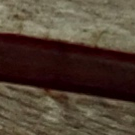

In [17]:
Image.fromarray(dataset[300]["image"]) #250

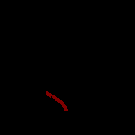

In [18]:
Image.fromarray(dataset[300]["mask_color"])

In [19]:
dataset[300]["measurements"]

{'coordinates_xy': '20,17',
 'length_mm': 2.074137443927347,
 'width_mm': 0.2506599275767845,
 'area_mm2': 0.4940179999999999}

In [20]:
dataset.measurements["area_mm2"] == 0

,area_mm2
filename,
Phyl_disc_0001.png,True
Phyl_disc_0002.png,True
Phyl_disc_0003.png,True
Phyl_disc_0004.png,True
Phyl_disc_0005.png,True
...,...
Phyl_disc_0906.png,True
Phyl_disc_0907.png,True
Phyl_disc_0908.png,True


In [ ]:
#dataset
    # offline
        #   preliminar EDA (class counts, duplicates, integrity)
        # 	train - test split (80/20) & stratification (mixed species, grouped by source image)
        #   cross validation (pre split folds)
        # 	wandb manifest export & import (format)
        #   EDA (stats, hard neg definition, etc...)
    # online
        # 	wandb manifest import as argument (for easy start)
        # 	transformations (resizing (species wise), agumentation (train-val wise))
        # 	dataset curation (hard negatives, neg-pos ratio, mask coverage dist, etc...)	
        # 	calss imbalance (weighted random sampler)

In [ ]:
# Data
# 256*256 tiled overlapping grid?
# Add new seg mask for wing area to calculate area mm2?
# Mark can draw on the whole image and then maybe tile it? YES!
# Issue on variable px mm conversion ratio
# Add image id apart from species id (for some species to have multiple source images)

In [23]:
from typing import Set, Dict

def download_manifest_deps(train_artifact: wandb.Artifact, test_artifact: wandb.Artifact) -> Tuple[Set[wandb.Artifact], Dict[str, str]]:

    run_artifacts = set(
            list(train_artifact.logged_by().used_artifacts()) +
            list(test_artifact.logged_by().used_artifacts()))
    
    # Check for non-compatible manifests
    artifact_names = set(art.name for art in run_artifacts if art.type == "dataset")
    if len(artifact_names) != len(set([art.split(":")[0] for art in artifact_names])):
        raise ValueError("Train & test set depend on different versions of the same dataset. Please ensure every version matches across manifests.")

    for artifact in run_artifacts:
        if artifact.name in os.listdir("data"): continue
        download_artifact(artifact.name)

    root_dirs = {art.name.split(":")[0].replace("-", "_") : f"data/{art.name}/dataset" for art in run_artifacts if art.type == "dataset"}

    return run_artifacts, root_dirs

In [24]:
from torch.utils.data import ConcatDataset
from sklearn.model_selection import StratifiedGroupKFold, KFold
from typing import Literal

def build_datasets(
    root_dirs:Dict[str, Union[str, os.PathLike]] = None,
    transforms:Dict[Literal["train", "test"], Union[A.Compose, None]] = {"train": None, "test": None},
    n_folds:int = 4,
    manifest_aliases:Dict[Literal["train", "test"], str] = None,
    current_fold: int = None,
    save_manifests: bool = False,
    eda: bool = False
    ) -> Tuple[ConcatDataset, ConcatDataset, ConcatDataset]:

    if manifest_aliases is not None:

        train_artifact, train_path = download_artifact(f"train-set:{manifest_aliases['train']}")
        test_artifact, test_path = download_artifact(f"test-set:{manifest_aliases['test']}")

        if root_dirs is None: _, root_dirs = download_manifest_deps(train_artifact, test_artifact)

    # Get master dataframe
    master_df = pd.concat(
        [pd.read_csv(os.path.join(root_dir, "measurements.csv")) for root_dir in root_dirs.values()],
        ignore_index=True
        )
    master_df["species"] = master_df["filename"].str[:9].str.lower()
    master_df["source_id"] = master_df["filename"].str[:9].str.lower() # TODO: Placeholder, implement this
    
    if not manifest_aliases:

        # Train-test 80/20 stratified split
        splitter = StratifiedGroupKFold(n_splits=5, shuffle=False)
        train_idxs, test_idxs = next(splitter.split(master_df, master_df["species"], groups=master_df["source_id"]))
        #train_df, test_df = master_df.iloc[train_idxs], master_df.iloc[test_idxs]
        train_df, test_df = master_df.iloc[np.concatenate([train_idxs, test_idxs])], master_df.iloc[test_idxs]
        # NOTE: TEMPORARY FIX TO ENSURE ALL DATA IS IN TRAIN SET FOR NOW, REMOVE LATER

        # CV splits on train_df
        cv_splitter = StratifiedGroupKFold(n_splits=n_folds, shuffle=False)
        cv_idxs = list(cv_splitter.split(train_df, train_df["species"], groups=train_df["source_id"]))
        # cv_splitter = KFold(n_splits=4, shuffle=False)
        # cv_idxs = list(cv_splitter.split(train_df))
        train_df = train_df.copy()
        train_df["val_fold"] = np.nan
        for fold, (_, val_idx) in enumerate(cv_idxs):
            train_df.loc[train_df.iloc[val_idx].index, "val_fold"] = fold

        if save_manifests:
            version_manifest(train_df, DatasetKind.TRAIN, transforms=transforms["train"])
            #version_manifest(test_df, DatasetKind.TEST, transforms=transforms["test"])

    else:
        
        train_df = pd.read_csv(train_path, index_col=0)
        test_df = pd.read_csv(test_path, index_col=0)
        
        train_transform_dict = train_artifact.metadata.get("transforms")
        test_transform_dict = test_artifact.metadata.get("transforms")

        if train_transform_dict and train_transform_dict != "None":
            transforms["train"] = A.from_dict(train_transform_dict)
            
        if test_transform_dict and test_transform_dict != "None":
            transforms["test"] = A.from_dict(test_transform_dict)

    # Build datasets
    train_datasets = []
    test_datasets = []
    val_datasets = []
    for species, root_dir in root_dirs.items():

        train_df_subset = train_df[(train_df["species"] == species)]
        test_df_subset = test_df[(test_df["species"] == species)]

        # Filter subsets to current fold if specified
        if current_fold is not None:
            val_df_fold = train_df_subset[train_df_subset["val_fold"] == current_fold]
            train_df_fold = train_df_subset[train_df_subset["val_fold"] != current_fold]
            train_df_subset, val_df_subset = train_df_fold, val_df_fold
        else: val_df_subset = train_df_subset

        ds_train = BatVeinDataset(
            root_dir=root_dir,
            measurements=train_df_subset.copy(),
            transform=transforms["train"],
            train_mode=(not eda))
        ds_val = BatVeinDataset(
            root_dir=root_dir,
            measurements=val_df_subset.copy(),
            transform=transforms["test"],
            train_mode=(not eda))
        ds_test = BatVeinDataset(
            root_dir=root_dir,
            measurements=test_df_subset.copy(),
            transform=transforms["test"],
            train_mode=(not eda))
        train_datasets.append(ds_train)
        val_datasets.append(ds_val)
        test_datasets.append(ds_test)

    return ConcatDataset(train_datasets), ConcatDataset(val_datasets), ConcatDataset(test_datasets)

In [25]:
# train, val, test = build_datasets(
#     manifest_aliases={
#         "train": "latest",
#         "test": "latest"
#     }
# )

In [26]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

transforms = {
    "train": A.Compose([
        # 1. Lossless Dihedral Symmetries + Smooth Affine
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Affine(
            scale=(0.85, 1.15),
            translate_percent=(-0.05, 0.05),
            rotate=(-30, 30),
            p=0.5
        ),

        # 2. Single Smooth Tissue Deformation (No double-warping or capillary tearing)
        A.OneOf([
            A.ElasticTransform(alpha=40, sigma=12.0),
            A.GridDistortion(num_steps=5, distort_limit=0.2)
        ], p=0.4),

        # 3. Photometric (Restores CLAHE to 50% frequency)
        A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.5),
        A.OneOf([
            A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
            A.RandomGamma(gamma_limit=(80, 120))
        ], p=0.5),

        # 4. Mild Sensor Noise & Blur
        A.OneOf([
            A.GaussianBlur(blur_limit=(3, 5)),
            A.GaussNoise(var_limit=(10.0, 50.0)),
            A.MotionBlur(blur_limit=3)
        ], p=0.3),

        # 5. Context Forcing (Probability dynamically controlled by config.data_cfg)
        A.CoarseDropout(max_holes=8, max_height=16, max_width=16, fill_value=0, p=0.15),

        # 6. Normalization
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ]),

    "test": A.Compose([
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])
}

/tmp/ipykernel_3273/1008181342.py:33: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0)),
/tmp/ipykernel_3273/1008181342.py:38: UserWarning: Argument(s) 'max_holes, max_height, max_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, fill_value=0, p=0.15),


In [27]:
# import albumentations as A
# from albumentations.pytorch import ToTensorV2

# transforms = {
#     "train": A.Compose([
#         # 1. Spatial/Geometric Invariance (Orientation & Scale)
#         A.HorizontalFlip(p=0.5),
#         A.VerticalFlip(p=0.5),
#         A.RandomRotate90(p=0.5),
#         A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=30, p=0.5), # NEW
        
#         # # 2. Tissue & Lens Deformation
#         #A.ElasticTransform(alpha=120, sigma=6.0, p=0.5),
#         A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3), # NEW
#         A.OneOf([
#             A.ElasticTransform(alpha=120, sigma=6.0),
#             A.GridDistortion(num_steps=5, distort_limit=0.3)
#         ], p=0.5),
        
#         # TODO: Check if group or RandomGamme is responsible for decline in perf
#         # 3. Photometric/Illumination (Grouped to prevent destroying data)
#         A.OneOf([
#             A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8)),
#             A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
#             A.RandomGamma(gamma_limit=(80, 120)) # NEW
#         ], p=0.8),

#         # A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.5),
#         # A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.5),
#         # # A.RandomGamma(gamma_limit=(80, 120), p=0.3), # NEW
        
#         # 4. Artifacts & Noise (Forces structural learning)
#         A.OneOf([
#             A.GaussianBlur(blur_limit=(3, 5)),
#             A.GaussNoise(var_limit=(10.0, 50.0)),
#             A.MotionBlur(blur_limit=3)
#         ], p=0.5),
        
#         # # 5. Context Forcing (Occlusion)
#         A.CoarseDropout(max_holes=10, max_height=16, max_width=16, fill_value=0, p=0.3), # NEW
        
#         # 6. Normalization
#         A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
#         ToTensorV2()
#     ]),
    
#     "test": A.Compose([
#         A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
#         ToTensorV2()
#     ])
# }

In [ ]:
# download_artifact("glos-comm:latest")
# download_artifact("hylo-unde:latest")
# download_artifact("phyl-disc:latest")
# download_artifact("derm-wats:latest")
# download_artifact("caro-cast:latest")
# download_artifact("lonc-conc:latest")
# download_artifact("caro-pers:latest")

In [ ]:
# train, val, test = build_datasets(
#     root_dirs={
#         "glos_comm": "data/glos-comm:v1/dataset",
#         "hylo_unde": "data/hylo-unde:v1/dataset",
#         "phyl_disc": "data/phyl-disc:v3/dataset",
#         "derm_wats": "data/derm-wats:v1/dataset",
#         "caro_cast": "data/caro-cast:v2/dataset",
#         "lonc_conc": "data/lonc-conc:v2/dataset",
#         "caro_pers": "data/caro-pers:v2/dataset"
#     },
#     transforms=transforms,
#     save_manifests=True
# )

In [30]:
import cv2
import matplotlib.pyplot as plt

def visualize_prediction(
        mask_pred: torch.Tensor,
        prob_pred: torch.Tensor,
        val_set: ConcatDataset,
        id: str,
        show: bool = False
        ) -> plt.Figure:

    master_df = pd.concat([ds.measurements for ds in val_set.datasets])
    sample = val_set[master_df.index.get_loc(id)]
    source_img = sample["image"]
    source_h, source_w = source_img.shape[:2]

    mask_pred = mask_pred.numpy()
    prob_pred = prob_pred.numpy()

    # Resize predictions if necessary
    if (source_h, source_w) != mask_pred.shape:
        mask_pred_resized = cv2.resize(
            mask_pred, 
            (source_w, source_h), 
            interpolation=cv2.INTER_NEAREST
        )
    
        prob_pred_resized = cv2.resize(
            prob_pred, 
            (source_w, source_h), 
            interpolation=cv2.INTER_LINEAR
        )
    else: mask_pred_resized, prob_pred_resized = mask_pred, prob_pred
    
    mask_overlay = source_img.copy()
    mask_overlay[mask_pred_resized == 1] = [0, 255, 0] # Green veins
    mask_overlay = cv2.addWeighted(source_img, 0.6, mask_overlay, 0.4, 0)

    prob_pred = (prob_pred_resized * 255).astype(np.uint8)
    heatmap_color = cv2.applyColorMap(prob_pred, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    prob_overlay = cv2.addWeighted(source_img, 0.5, heatmap_color, 0.5, 0)
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # Source image
    axes[0, 0].imshow(source_img)
    axes[0, 0].set_title(f"Source Image ({source_w}x{source_h})")
    axes[0, 0].axis("off")

    # Ground truth
    axes[0, 1].imshow(sample["mask_color"], cmap="gray")
    axes[0, 1].set_title("Ground Truth Mask")
    axes[0, 1].axis("off")
    
    # Predicted mask
    axes[0, 2].imshow(mask_pred_resized, cmap="gray")
    axes[0, 2].set_title("Predicted Mask")
    axes[0, 2].axis("off")
    
    # Predicted mask overlay
    axes[1, 0].imshow(mask_overlay)
    axes[1, 0].set_title("Predicted Mask Overlay")
    axes[1, 0].axis("off")
    
    # Predicted probability heatmap
    heatmap = axes[1, 1].imshow(prob_pred_resized, cmap="jet", vmin=0, vmax=1)
    axes[1, 1].set_title("Predicted Probability Heatmap (Raw Output)")
    axes[1, 1].axis("off")
    fig.colorbar(heatmap, ax=axes[1, 1], fraction=0.046, pad=0.04)
    
    # Predidcted probability overlay
    axes[1, 2].imshow(prob_overlay)
    axes[1, 2].set_title("Predicted Probability Overlay")
    axes[1, 2].axis("off")

    plt.tight_layout()

    if show: plt.show()

    return fig

In [31]:
from matplotlib.patches import Patch
from skimage.filters import apply_hysteresis_threshold

def _get_gaussian_window(height: int, width: int, sigma: float = 0.5) -> np.ndarray:
    y = np.linspace(-1, 1, height)
    x = np.linspace(-1, 1, width)
    y, x = np.meshgrid(y, x, indexing='ij')
    d = np.sqrt(x*x + y*y)
    g = np.exp(-(d**2) / (2.0 * sigma**2))
    return g

def stitch_predictions(
        val_set,
        source_id: str,
        prob_preds: torch.Tensor,
        overlap_pct: float = 0.0,
        decision_threshold: float = 0.5,
        gaussian_blending: bool = False,
        hysteresis_thresholds: Union[Tuple[float, float], None] = None # (low_thresh, high_thresh)
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:

    master_df = pd.concat([ds.measurements for ds in val_set.datasets])
    source_subset = master_df[master_df["source_id"] == source_id]
    if len(source_subset) == 0:  raise ValueError(f"Could not find any patches for source_id: {source_id}")
    
    coords = [list(map(int, xy.split(','))) for xy in source_subset["coordinates_xy"]]
    max_x = max([coord[0] for coord in coords])
    max_y = max([coord[1] for coord in coords])

    tile_h, tile_w = val_set[0]["image"].shape[:2]
    
    stride = int(tile_h * (1 - overlap_pct))
    canvas_h = (max_y * stride) + tile_h
    canvas_w = (max_x * stride) + tile_w

    # Initialize canvas
    canvas_source = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)
    canvas_true = np.zeros((canvas_h, canvas_w), dtype=np.uint8)
    canvas_pred = np.zeros((canvas_h, canvas_w), dtype=np.float32)
    weight_acc = np.zeros((canvas_h, canvas_w), dtype=np.float32)
    
    if gaussian_blending: gaussian_weight = _get_gaussian_window(tile_h, tile_w, sigma=0.5)
    else: gaussian_weight = np.ones((tile_h, tile_w), dtype=np.float32)
    
    # Add each tile to the canvas
    for id, row in source_subset.iterrows():
        x, y = map(int, row["coordinates_xy"].split(","))
        y = max_y - y
        
        sample = val_set[master_df.index.get_loc(id)]
        source_img = sample["image"]
        mask_true = sample["mask"].astype(np.uint8)

        pred_idx = master_df.index.get_loc(id)
        prob_pred = prob_preds[pred_idx].squeeze().numpy()
            
        if prob_pred.shape != (tile_h, tile_w):
            prob_pred = cv2.resize(prob_pred, (tile_w, tile_h), interpolation=cv2.INTER_LINEAR)
        
        y_start, y_end = y * stride, y * stride + tile_h
        x_start, x_end = x * stride, x * stride + tile_w
        
        canvas_source[y_start:y_end, x_start:x_end] = source_img
        canvas_true[y_start:y_end, x_start:x_end] = mask_true
        canvas_pred[y_start:y_end, x_start:x_end] += (prob_pred * gaussian_weight)
        weight_acc[y_start:y_end, x_start:x_end] += gaussian_weight

    weight_acc[weight_acc == 0] = 1.0
    canvas_pred_blended = canvas_pred / weight_acc
    if not hysteresis_thresholds:
        canvas_pred_bin = (canvas_pred_blended > decision_threshold).astype(np.uint8)
    else: 
        hysteresis_mask = apply_hysteresis_threshold(
            canvas_pred_blended, hysteresis_thresholds[0], hysteresis_thresholds[1])
        canvas_pred_bin = hysteresis_mask.astype(np.uint8)

    return canvas_source, canvas_true, canvas_pred_blended, canvas_pred_bin

def evaluate_predicted_wing(
        source_id: str,
        wing_source: np.ndarray,
        wing_true: np.ndarray,
        wing_pred_bin: np.ndarray,
        show: bool = False
        ) -> Tuple[plt.Figure, dict]:

    wing_h, wing_w = wing_true.shape[:2]

    tp_mask = (wing_true == 1) & (wing_pred_bin == 1)
    fp_mask = (wing_true == 0) & (wing_pred_bin == 1)
    fn_mask = (wing_true == 1) & (wing_pred_bin == 0)

    tp = np.sum(tp_mask)
    fp = np.sum(fp_mask)
    fn = np.sum(fn_mask)
    eps = 1e-6
    metrics = {
        "wing_iou": float(tp / (tp + fp + fn + eps)),
        "wing_dice": float((2 * tp) / ((2 * tp) + fp + fn + eps)),
        "wing_precision": float(tp / (tp + fp + eps)),
        "wing_recall": float(tp / (tp + fn + eps))
    }

    heatmap = np.zeros((wing_h, wing_w, 3), dtype=np.uint8)
    heatmap[tp_mask] = [0, 255, 0] # TP (Green)
    heatmap[fp_mask] = [255, 0, 0] # FP (Red)
    heatmap[fn_mask] = [0, 255, 255] # FN (Cyan)
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    axes[0, 0].imshow(wing_source)
    axes[0, 0].set_title(f"{source_id} - Source Wing", fontsize=14)
    axes[0, 0].axis("off")
    
    overlay = wing_source.copy()
    overlay[wing_pred_bin == 1] = [0, 255, 0]
    overlay = cv2.addWeighted(wing_source, 0.6, overlay, 0.4, 0)
    
    axes[0, 1].imshow(overlay)
    axes[0, 1].set_title("Predicted Mask Overlay", fontsize=14)
    axes[0, 1].axis("off")
    
    axes[1, 0].imshow(wing_true, cmap="gray")
    axes[1, 0].set_title("Ground Truth Mask", fontsize=14)
    axes[1, 0].axis("off")
    
    axes[1, 1].imshow(heatmap)
    axes[1, 1].set_title(f"Predicted Mask Error", fontsize=14)
    axes[1, 1].axis("off")

    legend_handles = [
        Patch(facecolor=[0, 1, 0], edgecolor="none", label="Correct (TP)"),
        Patch(facecolor=[1, 0, 0], edgecolor="none", label="Extra (FP)"),
        Patch(facecolor=[0, 1, 1], edgecolor="none", label="Missed (FN)")
    ]
    axes[1, 1].legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(0.02, 0.98),
        frameon=False,
        fontsize=10,
        labelcolor="white"
    )
    
    plt.tight_layout()

    if show: plt.show()

    return fig, metrics

In [32]:
"""
Centerline-Dice Loss Implementation
Adapted from https://github.com/jocpae/clDice to binary segmentation in modern PyTorch.
Paper: "clDice - a Novel Topology-Preserving Loss Function for Tubular Structure Segmentation"
"""

import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp

class SoftSkeletonize(torch.nn.Module):

    def __init__(self, num_iter=40):

        super(SoftSkeletonize, self).__init__()
        self.num_iter = num_iter

    def soft_erode(self, img):

        if len(img.shape)==4:
            p1 = -F.max_pool2d(-img, (3,1), (1,1), (1,0))
            p2 = -F.max_pool2d(-img, (1,3), (1,1), (0,1))
            return torch.min(p1,p2)
        elif len(img.shape)==5:
            p1 = -F.max_pool3d(-img,(3,1,1),(1,1,1),(1,0,0))
            p2 = -F.max_pool3d(-img,(1,3,1),(1,1,1),(0,1,0))
            p3 = -F.max_pool3d(-img,(1,1,3),(1,1,1),(0,0,1))
            return torch.min(torch.min(p1, p2), p3)

    def soft_dilate(self, img):

        if len(img.shape)==4:
            return F.max_pool2d(img, (3,3), (1,1), (1,1))
        elif len(img.shape)==5:
            return F.max_pool3d(img,(3,3,3),(1,1,1),(1,1,1))

    def soft_open(self, img):
        
        return self.soft_dilate(self.soft_erode(img))

    def soft_skel(self, img):

        img1 = self.soft_open(img)
        skel = F.relu(img-img1)

        for j in range(self.num_iter):
            img = self.soft_erode(img)
            img1 = self.soft_open(img)
            delta = F.relu(img-img1)
            skel = skel + F.relu(delta - skel * delta)

        return skel

    def forward(self, img):

        return self.soft_skel(img)

class soft_cldice(nn.Module):
    def __init__(self, iter_=3, smooth = 1., exclude_background=False):
        super(soft_cldice, self).__init__()
        self.iter = iter_
        self.smooth = smooth
        self.soft_skeletonize = SoftSkeletonize(num_iter=self.iter)
        self.exclude_background = exclude_background

    def forward(self, y_pred, y_true):
        y_pred = torch.sigmoid(y_pred)
        if self.exclude_background:
            y_true = y_true[:, 1:, :, :]
            y_pred = y_pred[:, 1:, :, :]
        skel_pred = self.soft_skeletonize(y_pred)
        skel_true = self.soft_skeletonize(y_true)
        tprec = (torch.sum(torch.multiply(skel_pred, y_true))+self.smooth)/(torch.sum(skel_pred)+self.smooth)    
        tsens = (torch.sum(torch.multiply(skel_true, y_pred))+self.smooth)/(torch.sum(skel_true)+self.smooth)    
        cl_dice = 1.- 2.0*(tprec*tsens)/(tprec+tsens)
        return cl_dice

def soft_dice(y_pred, y_true):
    smooth = 1.0
    intersection = torch.sum((y_true * y_pred), dim=(2, 3))
    union = torch.sum(y_true, dim=(2, 3)) + torch.sum(y_pred, dim=(2, 3))
    coeff = (2. * intersection + smooth) / (union + smooth)
    return (1. - coeff).mean()

class soft_dice_cldice(nn.Module):
    def __init__(self, iter_=3, alpha=0.5, exclude_background=False):
        super(soft_dice_cldice, self).__init__()
        self.iter = iter_
        self.alpha = alpha
        self.soft_skeletonize = SoftSkeletonize(num_iter=self.iter)
        self.exclude_background = exclude_background
        self.eps = 1e-5

    def forward(self, y_pred, y_true):

        y_pred = torch.sigmoid(y_pred) 


        # # --- DEBUG BLOCK ---
        # # Trigger only if recall is suspiciously high or loss is collapsing
        # if torch.rand(1).item() < 0.05:  # Sample 5% of batches to avoid console spam
        #     print(f"\n--- Diagnostics ---")
        #     print(f"y_true min/max/mean: {y_true.min().item():.2f} / {y_true.max().item():.2f} / {y_true.mean().item():.4f}")
        #     print(f"y_pred min/max/mean: {y_pred.min().item():.2f} / {y_pred.max().item():.2f} / {y_pred.mean().item():.4f}")

        #     # Check if the skeletonization is actually working
        #     skel_t = self.soft_skeletonize(y_true)
        #     print(f"skel_true sum: {torch.sum(skel_t).item():.2f}")
        #     print(f"-------------------\n")
                
        if self.exclude_background:
            y_true = y_true[:, 1:, :, :]
            y_pred = y_pred[:, 1:, :, :]
            
        dice = soft_dice(y_pred, y_true)
        
        skel_pred = self.soft_skeletonize(y_pred)
        skel_true = self.soft_skeletonize(y_true)
        
        tprec_num = torch.sum(skel_pred * y_true, dim=(2, 3))
        tprec_den = torch.sum(skel_pred, dim=(2, 3))
        tprec = tprec_num / (tprec_den + self.eps)
        
        tsens_num = torch.sum(skel_true * y_pred, dim=(2, 3))
        tsens_den = torch.sum(skel_true, dim=(2, 3))
        tsens = tsens_num / (tsens_den + self.eps)
        
        cl_dice_per_img = 1.0 - 2.0 * (tprec * tsens) / (tprec + tsens + self.eps)
        cl_dice = cl_dice_per_img.mean()
        
        return (1.0 - self.alpha) * dice + self.alpha * cl_dice
    

class soft_focal_dice_cldice(nn.Module):
    def __init__(self, iter_=3, alpha=0.5, exclude_background=False, focal_weight=5.0, dice_weight=1.0):
        super(soft_focal_dice_cldice, self).__init__()
        self.iter = iter_
        self.alpha = alpha
        self.exclude_background = exclude_background
        self.eps = 1e-5
        
        self.soft_skeletonize = SoftSkeletonize(num_iter=self.iter)
        
        # Initialize SMP Focal Loss (defaults to expecting raw logits)
        self.focal_loss_fn = smp.losses.FocalLoss(mode='binary', alpha=0.8, gamma=2.0)
        
        # Store the 5:1 ratio configuration
        self.focal_weight = focal_weight
        self.dice_weight = dice_weight

    def forward(self, y_pred_logits, y_true):
        # 1. Calculate Focal Loss using raw unactivated logits for mathematical stability
        focal = self.focal_loss_fn(y_pred_logits, y_true)
        
        # 2. Apply Sigmoid to bound predictions to [0, 1] for morphological pooling and Dice
        y_pred = torch.sigmoid(y_pred_logits) 

        if self.exclude_background:
            y_true = y_true[:, 1:, :, :]
            y_pred = y_pred[:, 1:, :, :]
            
        # 3. Calculate volumetric Dice Loss
        dice = soft_dice(y_pred, y_true)
        
        # 4. Blend Focal and Dice into a single volumetric base loss
        total_weight = self.focal_weight + self.dice_weight
        base_loss = (self.focal_weight / total_weight) * focal + (self.dice_weight / total_weight) * dice
        
        # 5. Calculate topological clDice
        skel_pred = self.soft_skeletonize(y_pred)
        skel_true = self.soft_skeletonize(y_true)
        
        tprec_num = torch.sum(skel_pred * y_true, dim=(2, 3))
        tprec_den = torch.sum(skel_pred, dim=(2, 3))
        tprec = tprec_num / (tprec_den + self.eps)
        
        tsens_num = torch.sum(skel_true * y_pred, dim=(2, 3))
        tsens_den = torch.sum(skel_true, dim=(2, 3))
        tsens = tsens_num / (tsens_den + self.eps)
        
        cl_dice_per_img = 1.0 - 2.0 * (tprec * tsens) / (tprec + tsens + self.eps)
        cl_dice = cl_dice_per_img.mean()
        
        # 6. Final Scheduled Output
        # epoch < 15: returns purely Focal + Dice (base_loss)
        # epoch > 15: blends in clDice topology penalty
        return (1.0 - self.alpha) * base_loss + self.alpha * cl_dice



In [33]:
from torch.utils.data import DataLoader, WeightedRandomSampler
import segmentation_models_pytorch as smp
from tqdm import tqdm
from typing import List

def train_model(
        model: smp.Unet,
        train: ConcatDataset[BatVeinDataset],
        val: ConcatDataset[BatVeinDataset],
        run_cfg: Dict[Literal[
            "name", "batch_size", "total_epochs",
            "early_stopping_patience", "frozen_epochs",
            "lr_frozen", "lr_finetune", "decision_threshold",
            "focal_gamma", "weight_decay"], Union[int, float]],
        device: torch.device,
        log_wandb: bool = True
        ) -> Tuple[Dict[str, float], str]:

    measurements = pd.concat([ds.measurements for ds in train.datasets])
    is_empty = measurements["area_mm2"] == 0
    sample_weights = np.zeros(len(train))
    sample_weights[is_empty] = 1.0 / is_empty.sum()
    sample_weights[~is_empty] = 1.0 / (~is_empty).sum()

    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(train),
        replacement=True
    )

    train_loader = DataLoader(
        dataset=train, 
        batch_size=run_cfg["batch_size"],
        sampler=sampler,
        shuffle=False,
        num_workers=0
    )

    val_loader = DataLoader(
        dataset=val,
        batch_size=run_cfg["batch_size"],
        shuffle=False,
        num_workers=0
    )

    for param in model.encoder.parameters(): param.requires_grad = False # Freeze encoder

    optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()), 
    lr=run_cfg["lr_frozen"],
    weight_decay=run_cfg["weight_decay"]
    )
    
    loss_focal = smp.losses.FocalLoss(mode="binary", alpha=0.8, gamma=run_cfg["focal_gamma"])
    #loss_bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([.5]).to(device))
    #loss_bce = nn.BCEWithLogitsLoss()
    loss_dice = smp.losses.DiceLoss(mode="binary")
    #loss_cldice = soft_dice_cldice(iter_=3, alpha=0.2)
    #loss_cldice = soft_focal_dice_cldice(iter_=3, alpha=0.5, focal_weight=5.0, dice_weight=1.0)
    #loss_cldice = soft_tversky_cldice(iter_=10, alpha=0.5, t_alpha=0.7, t_beta=0.3)
    #loss_tversky = smp.losses.TverskyLoss(mode="binary", alpha=0.3, beta=0.7)

    best_val_iou = 0.0
    best_model_metrics = {}

    # Fold loop
    for epoch in range(run_cfg["total_epochs"]):

        # Unfreeze encoder
        if epoch == run_cfg["frozen_epochs"]:
            for param in model.encoder.parameters(): param.requires_grad = True
            optimizer = torch.optim.AdamW(
                model.parameters(),
                lr=run_cfg["lr_finetune"],
                weight_decay=run_cfg["weight_decay"])

        model.train()
        train_loss = 0.0

        # Iterate through training batches from epoch
        train_bar = tqdm(train_loader, desc=f"TRAINING | Epoch {epoch+1}/{run_cfg['total_epochs']}")
        for batch in train_bar:
            images = batch["image_tensor"].to(device)
            masks = batch["mask_tensor"].to(device).float()

            optimizer.zero_grad()
            logits = model(images)
            loss = loss_dice(logits, masks) + (loss_focal(logits, masks) * 5.0)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_bar.set_postfix(loss=loss.item())

        avg_train_loss = train_loss / len(train_loader)
        
        model.eval()
        val_loss = 0.0
        tp, fp, fn = 0, 0, 0

        # Iterate through validation batches from epoch
        val_bar = tqdm(val_loader, desc=f"VALIDATION | Epoch {epoch+1}/{run_cfg['total_epochs']}")
        with torch.no_grad():
            for batch in val_bar:
                images = batch["image_tensor"].to(device)
                masks = batch["mask_tensor"].to(device).float()

                logits = model(images)
                loss = loss_dice(logits, masks) + (loss_focal(logits, masks) * 5.0)
                val_loss += loss.item()

                preds = (torch.sigmoid(logits) > run_cfg["decision_threshold"]).float()
                tp += (preds * masks).sum().item()
                fp += (preds * (1 - masks)).sum().item()
                fn += ((1 - preds) * masks).sum().item()

        # Log epoch validation metrics
        eps = 1e-6 # Avoids division by zero
        epoch_metrics = {
            "epoch": epoch,
            "lr": optimizer.param_groups[0]["lr"],
            "train_loss": avg_train_loss,
            "val_loss": val_loss / len(val_loader),
            "val_iou": tp / (tp + fp + fn + eps),
            "val_dice": (2 * tp) / ((2 * tp) + fp + fn + eps),
            "val_precision": tp / (tp + fp + eps),
            "val_recall": tp / (tp + fn + eps)}

        if log_wandb: wandb.log(epoch_metrics)

        # Save best model weights
        if epoch_metrics["val_iou"] > best_val_iou:
            best_val_iou = epoch_metrics["val_iou"]
            best_model_metrics = epoch_metrics
            model_name = run_cfg["name"].replace(" ", "_")
            weights_path = f"models/{model_name}__fold_{run_cfg["fold"]}.pth"
            torch.save(model.state_dict(), weights_path)
            print(f"FOLD {run_cfg["fold"]} | Saved new best model! Val Loss: {epoch_metrics['val_loss']:.4f}, IoU: {epoch_metrics['val_iou']:.4f}")

        # Early stopping check
        elif (epoch - best_model_metrics.get("epoch", 0)) >= run_cfg["early_stopping_patience"]:
            print(f"FOLD {run_cfg["fold"]} | Early stopping triggered. No improvement in {run_cfg['early_stopping_patience']} epochs.")
            break

    return best_model_metrics, weights_path

def predict(
        model: torch.nn.Module,
        weights_path: str,
        dataset: ConcatDataset[BatVeinDataset],
        device: torch.device,
        decision_threshold: float = 0.5,
        batch_size: int = 32,
        tta: bool = False
        ) -> Tuple[torch.Tensor, torch.Tensor, pd.DataFrame]:

    data_loader = DataLoader(
    dataset=dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
    )
    
    model.load_state_dict(torch.load(weights_path))
    model.eval()

    for ds in dataset.datasets: ds.train_mode = False
    
    mask_preds = []
    prob_preds = []
    df_list = []
    
    with torch.no_grad():

        pred_bar = tqdm(data_loader, desc=f"INFERENCE")
        
        for batch in pred_bar:

            images = batch["image_tensor"].to(device)

            if tta:

                vanilla_probs = torch.sigmoid(model(images))
                
                horizontal_flip = torch.flip(images, dims=[-1])
                h_flip_probs = torch.flip(torch.sigmoid(model(horizontal_flip)), dims=[-1])
                
                vertical_flip = torch.flip(images, dims=[-2])
                v_flip_probs = torch.flip(torch.sigmoid(model(vertical_flip)), dims=[-2])
                
                half_turn_flip = torch.flip(images, dims=[-2, -1])
                ht_flip_probs = torch.flip(torch.sigmoid(model(half_turn_flip)), dims=[-2, -1])
                
                probs = (vanilla_probs + h_flip_probs + v_flip_probs + ht_flip_probs) / 4.0

            else: probs = torch.sigmoid(model(images))

            preds = (probs > decision_threshold).to(torch.uint8).squeeze(1).cpu()

            mask_preds.append(preds)
            prob_preds.append(probs.squeeze().cpu())
            df_list.append(pd.DataFrame(batch["measurements"], index=batch["id"]))

    return torch.cat(mask_preds, dim=0), torch.cat(prob_preds, dim=0), pd.concat(df_list)

def cross_validate(
        manifest_aliases: Dict[Literal["train", "test"], str],
        cv_cfg: Dict[Literal["batch_size", "total_epochs", "frozen_epochs", "lr_frozen", "lr_finetune", "decision_threshold"], Union[int, float]] = {},
        folds: List[int] = None,
        version_models: bool = True
        ) -> None:

    train_manifest = download_artifact(f"train-set:{manifest_aliases['train']}")[0]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Wandb run configs
    if folds and len(folds) == 1:
        cv_name = None
        fold_name = f"Fold {folds[0]} {datetime.now().strftime('%Y%m%d_%H%M%S')}"
    else:
        folds = list(range(train_manifest.metadata.get("n_folds", 4)))
        cv_name = f"Cross-Validation {datetime.now().strftime('%Y%m%d_%H%M%S')}"

    model_cfg = {
        "architecture": "Unet",
        "encoder_name": "resnet50",
        "encoder_weights": "imagenet",
        "activation": "sigmoid", 
    }
    run_cfg = {
        "name": cv_name if cv_name else fold_name,
        "total_folds": len(folds),
        "fold_list": folds,
        "sampler_strategy": "inverse_frequency", 
        "batch_size": cv_cfg.get("batch_size", 32),
        "total_epochs": cv_cfg.get("total_epochs", 50),
        "early_stopping_patience": cv_cfg.get("early_stopping_patience", 50),
        "frozen_epochs": cv_cfg.get("frozen_epochs", 10),
        "optimizer": "AdamW",
        "lr_frozen": cv_cfg.get("lr_frozen", 1e-3),
        "lr_finetune": cv_cfg.get("lr_finetune", 1e-5),
        "loss_function": "Focal_plus_Dice",
        "loss_weights": {"dice":1.0, "focal":5.0},
        "decision_threshold": cv_cfg.get("decision_threshold", 0.5),
        "focal_gamma": cv_cfg.get("focal_gamma", 2.0),
        "weight_decay": cv_cfg.get("weight_decay", 1e-2)
    }
    preprocessing_cfg = {
        "gaussian_blending": cv_cfg.get("gaussian_blending", False),
        "hysteresis_thresholds": cv_cfg.get("hysteresis_thresholds", None),
        "test_time_augmentation": cv_cfg.get("hysteresis_thresholds", False)
    }
    cv_cfg = {"run": run_cfg, "model": model_cfg, "preprocessing": preprocessing_cfg}

    for fold in folds:

        # Start wandb run
        run_cfg["fold"] = fold

        run = wandb.init(
        project="Vein Length Estimator",
        group=cv_name,
        job_type="training",
        name=f"Fold {fold}" if cv_name else fold_name,
        save_code=True,
        config=cv_cfg)

        run.use_artifact(f"train-set:{manifest_aliases['train']}", type="manifest")

        # Load fold datasets
        train, val, _ = build_datasets(
            manifest_aliases=manifest_aliases,
            current_fold=fold)

        #for ds in train.datasets: ds.transform = transforms["train"]

        # Initialize components
        model = smp.Unet(
            encoder_name=model_cfg["encoder_name"], 
            encoder_weights=model_cfg["encoder_weights"], 
            in_channels=3, 
            classes=1,
            decoder_attention_type="scse"
        ).to(device)

        # For SwAV: "https://dl.fbaipublicfiles.com/deepcluster/swav_800ep_pretrain.pth.tar"
        # For MoCo v2: "https://dl.fbaipublicfiles.com/moco/moco_checkpoints/moco_v2_800ep/moco_v2_800ep_pretrain.pth.tar"
        # ssl_url = "https://dl.fbaipublicfiles.com/deepcluster/swav_800ep_pretrain.pth.tar"
        # checkpoint = torch.hub.load_state_dict_from_url(ssl_url, map_location=device)
        # state_dict = checkpoint.get("state_dict", checkpoint)
        # clean_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
        # model.encoder.load_state_dict(clean_dict, strict=False)

        # print("SSL weights successfully injected into the encoder!")

        # Train model
        best_model_metrics, weights_path = train_model(
            model=model,
            train=train,
            val=val,
            run_cfg=run_cfg,
            device=device,
            log_wandb=True
        )

        # Predict validation set
        mask_preds, prob_preds, val_df = predict(
            model=model,
            weights_path=weights_path,
            dataset=val,
            device=device,
            decision_threshold=run_cfg["decision_threshold"],
            tta=preprocessing_cfg["test_time_augmentation"]
        )

        wandb_tiles = []
        wing_table = wandb.Table(columns=[
            "source_id", "wing_visualization", "wing_iou", "wing_dice", "wing_precision", "wing_recall"])

        upstream_datasets = train_manifest.logged_by().used_artifacts()
        overlap_dict = {art.name.split(":")[0].replace("-", "_"):art.metadata.get("overlap", 0.0) for art in upstream_datasets}
        
        for source_id in val_df["source_id"].unique():

            wing_source, wing_true, _, wing_pred_bin = stitch_predictions(
                val_set=val,
                source_id=source_id,
                prob_preds=prob_preds,
                overlap_pct=overlap_dict[source_id],
                decision_threshold=run_cfg["decision_threshold"],
                gaussian_blending=preprocessing_cfg["gaussian_blending"],
                hysteresis_thresholds=preprocessing_cfg["hysteresis_thresholds"]
            )

            wing_fig, wing_metrics = evaluate_predicted_wing(
                source_id=source_id,
                wing_source=wing_source,
                wing_true=wing_true,
                wing_pred_bin=wing_pred_bin,
                show=False
            )

            wing_table.add_data(
                source_id,
                wandb.Image(wing_fig, caption=f"Stitched: {source_id}"),
                *wing_metrics.values()
            )

            wing_subset = val_df[val_df["source_id"] == source_id]
            tile_id = wing_subset["area_mm2"].idxmax() 
            tile_idx = val_df.index.get_loc(tile_id)

            tile_fig = visualize_prediction(
                mask_pred=mask_preds[tile_idx],
                prob_pred=prob_preds[tile_idx],
                val_set=val,
                id=tile_id,
                show=False
            )
            wandb_tiles.append(wandb.Image(tile_fig, caption=f"Best Tile: {source_id}"))

            plt.close(wing_fig)
            plt.close(tile_fig)

        wing_metrics_df = wing_table.get_dataframe()
        wandb.summary["avg_wing_iou"] = wing_metrics_df["wing_iou"].mean()
        wandb.summary["avg_wing_dice"] = wing_metrics_df["wing_dice"].mean()
        wandb.summary["avg_wing_precision"] = wing_metrics_df["wing_precision"].mean()
        wandb.summary["avg_wing_recall"] = wing_metrics_df["wing_recall"].mean()

        wandb.log({
            "Wing Table": wing_table,
            "Tile Visualization": wandb_tiles
        })

        if len(folds) > 1 and version_models:

            model_weights_art = wandb.Artifact(
                name=f"unet-f{fold}",
                type="weights",
                description=f"Best model weights for fold {fold} of {cv_name}",
                metadata= {"metrics": best_model_metrics, "specs": model_cfg}
            )
            
            model_weights_art.add_file(weights_path)
            run.log_artifact(model_weights_art)
        
        run.finish()

In [ ]:
# cross_validate(
#     cv_cfg={
#         "batch_size": 32,
#         "total_epochs": 50,
#         "frozen_epochs": 10,
#         "early_stopping_patience": 50,
#         "lr_frozen": 1e-3,
#         "lr_finetune": 7.3e-5,
#         "decision_threshold": 0.5,
#         "gaussian_blending": True,
#         "hysteresis_thresholds": None,#(0.5, 0.9),
#         "test_time_augmentation": False,
#         "focal_gamma": 2.3,
#         "weight_decay": 1e-3
#     },
#     manifest_aliases={
#         "train": "latest",
#         "test": "v4"
#     },
#     folds=[0, 1, 2, 3],
#     version_models=True
# )

In [37]:
import json
import subprocess
import threading
import cloudpickle
import sys
import time
import copyreg
import importlib

copyreg.pickle(
    type(torch.backends.cudnn),
    lambda m: (importlib.import_module, (m.__name__,))
)

copyreg.pickle(type(wandb.Api()), lambda a: (wandb.Api, ()))
copyreg.pickle(type(threading.Lock()), lambda l: (threading.Lock, ()))
copyreg.pickle(type(threading.RLock()), lambda l: (threading.RLock, ()))

exploration_sweep_config = {
    "method": "random",
    "name": "2nd Gen w/ SCSE Hyperparameter Importance",
    "metric": {
        "name": "val_iou",
        "goal": "maximize"
    },
    "early_terminate": {
        "type": "hyperband",
        "min_iter": 9,
        "eta": 3
    },
    "parameters": {
        "sweep_cfg": {
            "parameters": {
                "inference_only": {"value": False},
                "weights_alias": {"value": "latest"},
                "save_best_weights": {"value": False}
            }
        },
        "preprocessing_cfg": {
            "parameters": {
                "hysteresis_thresholds": {"value": None}
            }
        },
        "run_cfg": {
            "parameters": {
                "total_epochs": {"value": 25},
                "frozen_epochs": {"value": 5},
                "early_stopping_patience": {"value": 10},

                "focal_weight": {
                    "distribution": "int_uniform",
                    "min": 1,
                    "max": 10
                },
                "dice_weight": {
                    "distribution": "int_uniform",
                    "min": 1,
                    "max": 5
                },
                "focal_gamma": {
                    "distribution": "uniform",
                    "min": 1.0,
                    "max": 3.5
                },
                "lr_finetune": {
                    "distribution": "log_uniform_values",
                    "min": 1e-6,
                    "max": 1e-4
                },
                "weight_decay": {
                    "distribution": "log_uniform_values",
                    "min": 1e-5,
                    "max": 1e-2
                }
            }
        },
        "data_cfg": {
            "parameters": {
                "coarse_dropout_p": {
                    "distribution": "uniform",
                    "min": 0.0,
                    "max": 0.5
                },
                "train_alias": {"value": "latest"},
                "test_alias": {"value": "v4"},
                "fold": {"value": 0}
            }
        }
    }
}

fine_sweep_config = {
    "method": "bayes",
    "name": "Fold 0 - 2nd Gen w/ SCSE Fine Optimization",
    "metric": {
        "name": "avg_wing_iou",
        "goal": "maximize"
    },
    "parameters": {
        "sweep_cfg": {
            "parameters": {
                "inference_only": {"value": False},
                "weights_alias": {"value": "latest"},
                "save_best_weights": {"value": True}
            }
        },
        "preprocessing_cfg": {
            "parameters": {
                "hysteresis_thresholds": {"value": None}
            }
        },
        "run_cfg": {
            "parameters": {

                "total_epochs": {"value": 50},
                "frozen_epochs": {"value": 10},
                "early_stopping_patience": {"value": 12},

                "lr_finetune": {
                    "distribution": "log_uniform_values",
                    "min": 1.5e-5,
                    "max": 1.2e-4
                },
                "dice_weight": {"value": 1},
                "focal_weight": {
                    "distribution": "int_uniform",
                    "min": 1,
                    "max": 5
                },
                "focal_gamma": {
                    "distribution": "uniform",
                    "min": 2.0,
                    "max": 3.5
                },
                "weight_decay": {"value": 1e-3}
            }
        },
        "data_cfg": {
            "parameters": {
                "coarse_dropout_p": {
                    "distribution": "uniform",
                    "min": 0.0,
                    "max": 0.20
                },
                "train_alias": {"value": "latest"},
                "test_alias": {"value": "v4"},
                "fold": {"value": 0}
            }
        }
    }
}

postprocessing_sweep_config = {
    "method": "grid",
    "name": "Fold 1 - 3rd Gen Postprocessing Optimization v2",
    "metric": {
        "name": "avg_wing_iou",
        "goal": "maximize"
    },
    "parameters": {
        "sweep_cfg": {
            "parameters": {
                "inference_only": {"value": True},
                "weights_alias": {"value": "latest"},
                "save_best_weights": {"value": False}
            }
        },
        "preprocessing_cfg": {
            "parameters": {
                "gaussian_blending": {"values": [False, True]},
                "test_time_augmentation": {"values": [False, True]},
                "hysteresis_thresholds": {
                    "values": [
                        None,
                        [0.15, 0.45],
                        [0.20, 0.50],
                        [0.20, 0.60],
                        [0.25, 0.55],
                        [0.30, 0.65],
                        [0.35, 0.70],
                        [0.4, 0.75],
                        [0.45, 0.80],
                        [0.50, 0.85]
                    ]
                }
            }
        },
        "run_cfg": {
            "parameters": {
                "decision_threshold": {"value": 0.5}
            }
        },
        "data_cfg": {
            "parameters": {
                "train_alias": {"value": "latest"},
                "test_alias": {"value": "v4"},
                "fold": {"value": 1}
            }
        }
    }
}

def _stream_worker_logs(pipe, worker_id: int) -> None:
    for line in iter(pipe.readline, ""):
        if line: print(f"[Worker {worker_id}] {line}", end="", flush=True)
    pipe.close()

def sweep():

    wandb.init()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    config = wandb.config
    current_fold = config.data_cfg["fold"]

    model_cfg = {
    "architecture": "Unet",
    "encoder_name": "resnet50",
    "encoder_weights": "imagenet",
    "activation": "sigmoid", 
    }

    run_cfg = {
        "fold": current_fold,
        "name": f"Fold {current_fold} {wandb.run.id}",
        "total_folds": 1,
        "fold_list": [current_fold],
        "sampler_strategy": "inverse_frequency",
        "batch_size": config.run_cfg.get("batch_size", 32),
        "total_epochs": config.run_cfg.get("total_epochs", 50),
        "early_stopping_patience": config.run_cfg.get("early_stopping_patience", 50),
        "frozen_epochs": config.run_cfg.get("frozen_epochs", 10),
        "optimizer": "AdamW",
        "lr_frozen": config.run_cfg.get("lr_frozen", 1e-3),
        "lr_finetune": config.run_cfg.get("lr_finetune", 1e-5),
        "loss_function": "Focal_plus_Dice",
        "loss_weights": {
            "dice": config.run_cfg.get("dice_weight", 1.0),
            "focal": config.run_cfg.get("focal_weight", 5.0)},
        "decision_threshold": config.run_cfg.get("decision_threshold", 0.5),
        "focal_gamma": config.run_cfg.get("focal_gamma", 2.0),
        "weight_decay": config.run_cfg.get("weight_decay", 1e-2)
    }
    
    preprocessing_cfg = {
        "gaussian_blending": config.preprocessing_cfg.get("gaussian_blending", False),
        "hysteresis_thresholds": config.preprocessing_cfg.get("hysteresis_thresholds", None),
        "test_time_augmentation": config.preprocessing_cfg.get("test_time_augmentation", False)
    }

    sweep_run_cfg = {"run": run_cfg, "model": model_cfg, "preprocessing": preprocessing_cfg}
    wandb.config.update(sweep_run_cfg, allow_val_change=True)

    train, val, _ = build_datasets(
    manifest_aliases={
        "train": config.data_cfg["train_alias"],
        "test": config.data_cfg["test_alias"]
    },
    current_fold=current_fold)

    for ds in train.datasets:
        dropout_layer = next(t for t in ds.transform.transforms if isinstance(t, A.CoarseDropout))
        dropout_layer.p = config.data_cfg.get("coarse_dropout_p", 0.0)

    wandb.use_artifact(f"train-set:{config.data_cfg['train_alias']}")

    if config.sweep_cfg.get("inference_only", False):

        model = smp.Unet(
            encoder_name=model_cfg["encoder_name"], 
            encoder_weights=None,
            in_channels=3, 
            classes=1,
            decoder_attention_type="scse"
        ).to(device)

        _, weights_path = download_artifact(f"unet-f{current_fold}:{config.sweep_cfg['weights_alias']}")

    else:

        model = smp.Unet(
            encoder_name=model_cfg["encoder_name"],
            encoder_weights=model_cfg["encoder_weights"],
            in_channels=3,
            classes=1,
            decoder_attention_type="scse"
        ).to(device)

        best_model_metrics, weights_path = train_model(
            model = model,
            train = train,
            val = val,
            run_cfg = run_cfg,
            device = device,
            log_wandb = True
        )

    _, prob_preds, val_df = predict(
        model=model,
        weights_path=weights_path,
        dataset=val,
        device=device,
        decision_threshold=run_cfg["decision_threshold"],
        tta=preprocessing_cfg["test_time_augmentation"]
    )

    train_manifest = download_artifact(f"train-set:{config.data_cfg['train_alias']}")[0]
    upstream_datasets = train_manifest.logged_by().used_artifacts()
    overlap_dict = {art.name.split(":")[0].replace("-", "_"):art.metadata.get("overlap", 0.0) for art in upstream_datasets}

    wing_iou_cum, wing_recall_cum, wing_precision_cum = 0.0, 0.0, 0.0
    source_ids = val_df["source_id"].unique()
    
    for source_id in source_ids:

        wing_source, wing_true, _, wing_pred_bin = stitch_predictions(
            val_set=val,
            source_id=source_id,
            prob_preds=prob_preds,
            overlap_pct=overlap_dict[source_id],
            decision_threshold=run_cfg["decision_threshold"],
            gaussian_blending=preprocessing_cfg["gaussian_blending"],
            hysteresis_thresholds=preprocessing_cfg["hysteresis_thresholds"]
        )

        wing_fig, wing_metrics = evaluate_predicted_wing(
            source_id=source_id,
            wing_source=wing_source,
            wing_true=wing_true,
            wing_pred_bin=wing_pred_bin,
            show=False
        )

        plt.close(wing_fig)

        wing_iou_cum += wing_metrics["wing_iou"]
        wing_recall_cum += wing_metrics["wing_recall"]
        wing_precision_cum += wing_metrics["wing_precision"]
        
    final_metrics = {
        "avg_wing_iou": wing_iou_cum / len(source_ids),
        "avg_wing_recall": wing_recall_cum / len(source_ids),
        "avg_wing_precision": wing_precision_cum / len(source_ids)
    }
    wandb.log(final_metrics)

    if config.sweep_cfg.get("save_best_weights", False):
        with open(f"misc/metrics_{wandb.run.id}.json", "w") as f:
            json.dump(best_model_metrics, f)
    else:  os.remove(weights_path)

    wandb.finish()

def run_sweep(sweep_config: dict, num_workers: int, total_runs: int) -> None:

    sweep_params = sweep_config["parameters"]["sweep_cfg"]["parameters"]
    data_params = sweep_config["parameters"]["data_cfg"]["parameters"]
    fold = data_params["fold"]["value"]

    train_alias = data_params["train_alias"]["value"]
    test_alias = data_params["test_alias"]["value"]
    print("Pre-caching dataset artifacts...")
    train_art, _ = download_artifact(f"train-set:{train_alias}")
    test_art, _ = download_artifact(f"test-set:{test_alias}")
    download_manifest_deps(train_art, test_art)
    if sweep_params.get("inference_only", {}).get("value", False):
        print("Pre-caching model weights...")
        download_artifact(f"unet-f{fold}:{sweep_params["weights_alias"]["value"]}")

    sweep_id = wandb.sweep(sweep_config, project="Vein Length Estimator")

    if num_workers == 1:
        wandb.agent(sweep_id, function=sweep, count=total_runs, project="Vein Length Estimator")
    else:

        pkl_path = "misc/sweep_fn.pkl"
        with open(pkl_path, "wb") as f:
            cloudpickle.dump(sweep, f)

        processes = []
        log_threads = []

        for i in range(num_workers):
            worker_runs = (total_runs // num_workers) + (1 if i < (total_runs % num_workers) else 0)
            worker_code = (
                "import os, time, cloudpickle, wandb\n"
                "os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'\n"
                f"time.sleep({i * 3})\n"
                f"print('Connecting to W&B sweep {sweep_id} for {worker_runs} runs...', flush=True)\n"
                f"with open('{pkl_path}', 'rb') as f:\n"
                "    sweep_fn = cloudpickle.load(f)\n"
                f"wandb.agent('{sweep_id}', function=sweep_fn, count={worker_runs}, project='Vein Length Estimator')\n"
            )

            p = subprocess.Popen(
                [sys.executable, "-u", "-c", worker_code],
                stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT,
                text=True,
                bufsize=1
            )
            processes.append(p)

            t = threading.Thread(target=_stream_worker_logs, args=(p.stdout, i), daemon=True)
            t.start()
            log_threads.append(t)

        try:
            for p in processes:
                p.wait()
            for t in log_threads:
                t.join(timeout=2)
        except KeyboardInterrupt:
            print("\nInterrupt received! Terminating parallel sweep workers...")
            for p in processes:
                p.terminate()
            return

    if sweep_params["save_best_weights"]["value"]:

        print("Sweep complete. Identifying the best model...")

        api = wandb.Api() 
        sweep_obj = api.sweep(f"dimi3/Vein Length Estimator/{sweep_id}")
        best_run = sorted(sweep_obj.runs, key=lambda r: r.summary.get("avg_wing_iou", 0), reverse=True)[0]

        print(f"Winner: {best_run.name} (ID: {best_run.id}) | IoU: {best_run.summary.get('avg_wing_iou')}")

        with wandb.init(project="Vein Length Estimator", id=best_run.id, resume="must") as run:

            with open(f"misc/metrics_{best_run.id}.json", "r") as f:
                best_model_metrics = json.load(f)
            
            model_weights_art = wandb.Artifact(
                name=f"unet-f{fold}",
                type="weights",
                description=f"Best model weights for fold {fold} of sweep {sweep_config['name']}",
                metadata= {"metrics": best_model_metrics, "specs": best_run.config["model"]}
                )

            model_name = f"Fold_{fold}_{sweep_id}"
            model_weights_art.add_file(f"models/{model_name}__fold_{fold}.pth")
            run.log_artifact(model_weights_art)
            
            print("Successfully uploaded the best model weights to the cloud.")

        for file in glob.glob("models/*fold_*.pth"): os.remove(file)
    
        print("Local disk cleanup complete.")

In [38]:
run_sweep(postprocessing_sweep_config, num_workers=3, total_runs=36)

Pre-caching dataset artifacts...
Pre-caching model weights...


wandb: Downloading large artifact 'unet-f1:latest', 129.37MB. 1 files...
wandb:   1 of 1 files downloaded.  
Done. 00:00:10.7 (12.1MB/s)


Create sweep with ID: uvkeikdr
Sweep URL: https://wandb.ai/dimi3/Vein%20Length%20Estimator/sweeps/uvkeikdr
[Worker 0] Connecting to W&B sweep uvkeikdr for 12 runs...
[Worker 1] Connecting to W&B sweep uvkeikdr for 12 runs...
[Worker 0] wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
[Worker 2] Connecting to W&B sweep uvkeikdr for 12 runs...
[Worker 0] wandb: Agent Starting Run: an6ch2dk with config:
[Worker 0] wandb: 	data_cfg: {'fold': 1, 'test_alias': 'v4', 'train_alias': 'latest'}
[Worker 0] wandb: 	preprocessing_cfg: {'gaussian_blending': False, 'hysteresis_thresholds': None, 'test_time_augmentation': False}
[Worker 0] wandb: 	run_cfg: {'decision_threshold': 0.5}
[Worker 0] wandb: 	sweep_cfg: {'inference_only': True, 'save_best_weights': False, 'weights_alias': 'latest'}
[Worker 0] wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
[Worker 0] wandb: Currently logged in as: dimi3 to https://api.wandb.ai. Use `wan

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train, val, test = build_datasets(
    manifest_aliases={
        "train": "latest",
        "test": "latest"
    },
    eda=True,
    current_fold=0
)

val_loader = DataLoader(
    dataset=val,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

weights_art, weights_path = download_artifact(f"unet-f0:latest")

model = smp.Unet(
    encoder_name="resnet50", 
    encoder_weights=None,
    in_channels=3, 
    classes=1
).to(device)

model.load_state_dict(torch.load(weights_path, map_location=device))

wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb: Downloading large artifact 'hylo-unde:v1', 114.79MB. 3046 files...
Done. 00:00:10.6 (10.8MB/s)of 3046 files downloaded...
wandb: Downloading large artifact 'lonc-conc:v2', 79.75MB. 2371 files...
Done. 00:00:08.2 (9.7MB/s) of 2371 files downloaded...
wandb: Downloading large artifact 'caro-cast:v2', 118.43MB. 3023 files...
Done. 00:00:10.1 (11.7MB/s)of 3023 files downloaded...
wandb: Downloading large artifact 'derm-wats:v1', 93.02MB. 2376 files...
Done. 00:00:08.3 (11.3MB/s)of 2376 files downloaded...
wandb: Downloading large artifact 'glos-comm:v1', 87.34MB. 2310 files...
Done. 00:00:07.6 (11.4MB/s)of 2310 files downloaded...
wandb: Downloading large artifact 'phyl-disc:v3', 124.96MB. 3082 files...
Done. 00:00:09.8 (12.8MB/s)of 3082 files downloaded...
wandb: Downloading large artifact 'caro-pers:v2', 108.48MB. 3185 files...
Done. 00:00:10.8 (10.1MB/s)of 3185 files downloaded...
wandb: Downloading large art

<All keys matched successfully>

In [68]:
mask_preds, prob_preds, val_df = predict(
    model=model,
    weights_path=weights_path,
    dataset=val,
    device=device,
    decision_threshold=0.5,
    tta=True
)

INFERENCE: 100%|██████████| 40/40 [00:40<00:00,  1.02s/it]


In [41]:
val_df.source_id.unique()

array(['derm_wats', 'caro_cast'], dtype=object)

In [85]:
wing_source, wing_true, _, wing_pred_bin = stitch_predictions(
    val_set=val,
    source_id="derm_wats",
    prob_preds=prob_preds,
    overlap_pct=0.4,
    decision_threshold=0.5,
    gaussian_blending=True,
    hysteresis_thresholds=(0.5, 0.9)
)

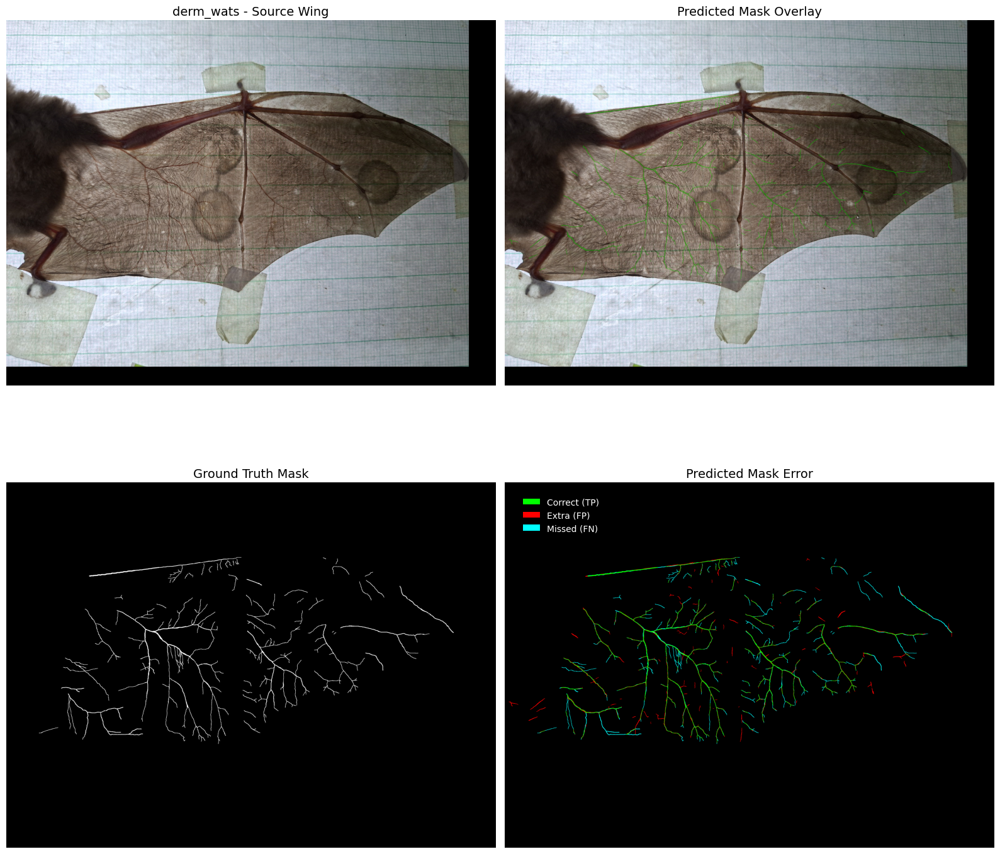

In [86]:
_, wing_metrics = evaluate_predicted_wing(
    source_id="derm_wats",
    wing_source=wing_source,
    wing_true=wing_true,
    wing_pred_bin=wing_pred_bin,
    show=True
)

In [87]:
wing_metrics

{'wing_iou': 0.42738409616140854,
 'wing_dice': 0.5988354463395674,
 'wing_precision': 0.6210402286447329,
 'wing_recall': 0.5781636797514255}

/tmp/ipykernel_5168/2428171916.py:109: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(2, 2, figsize=(16, 16))


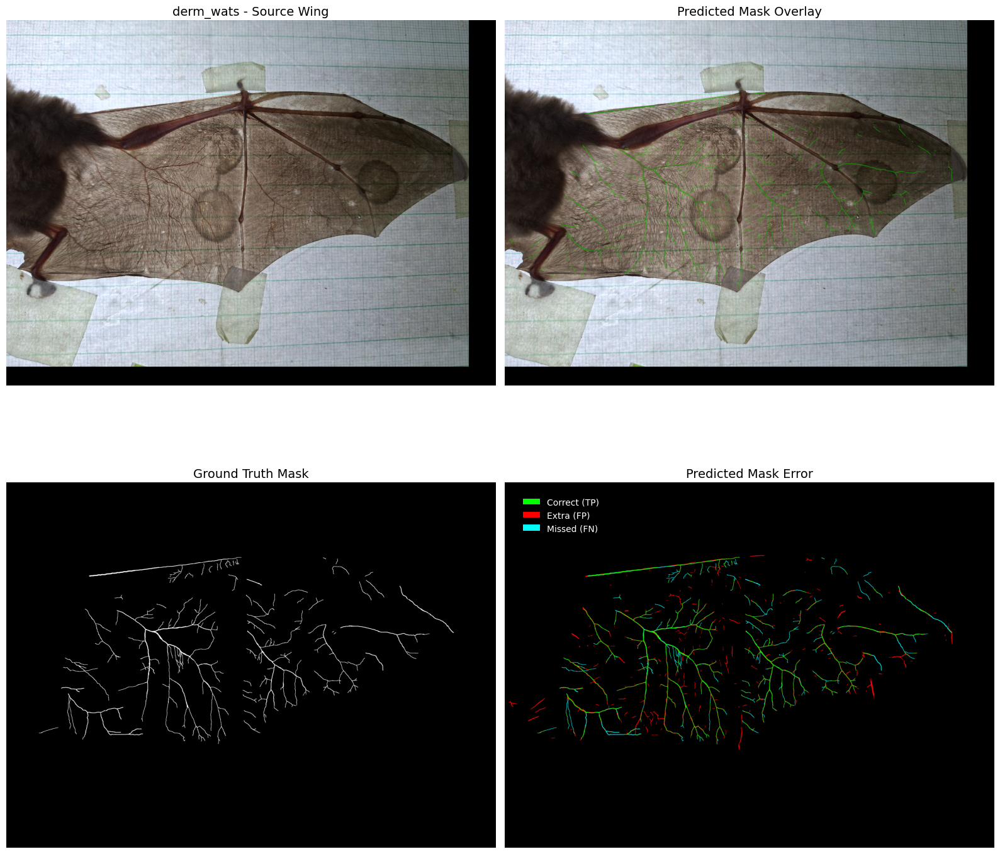

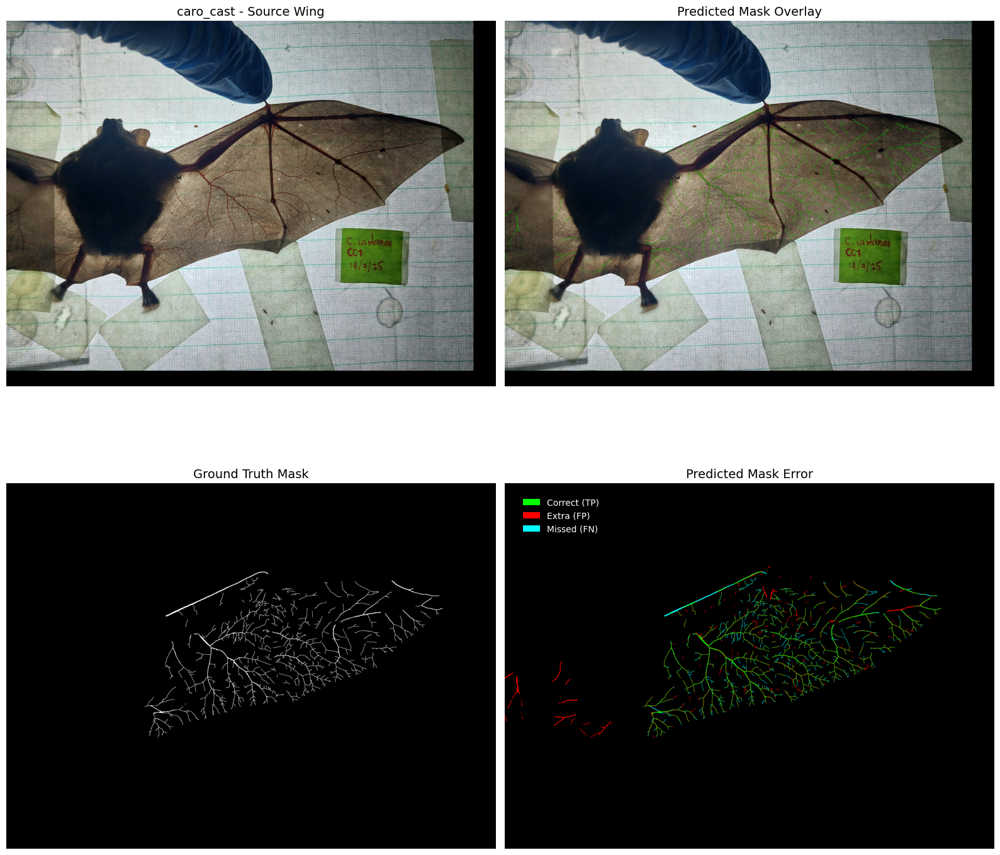

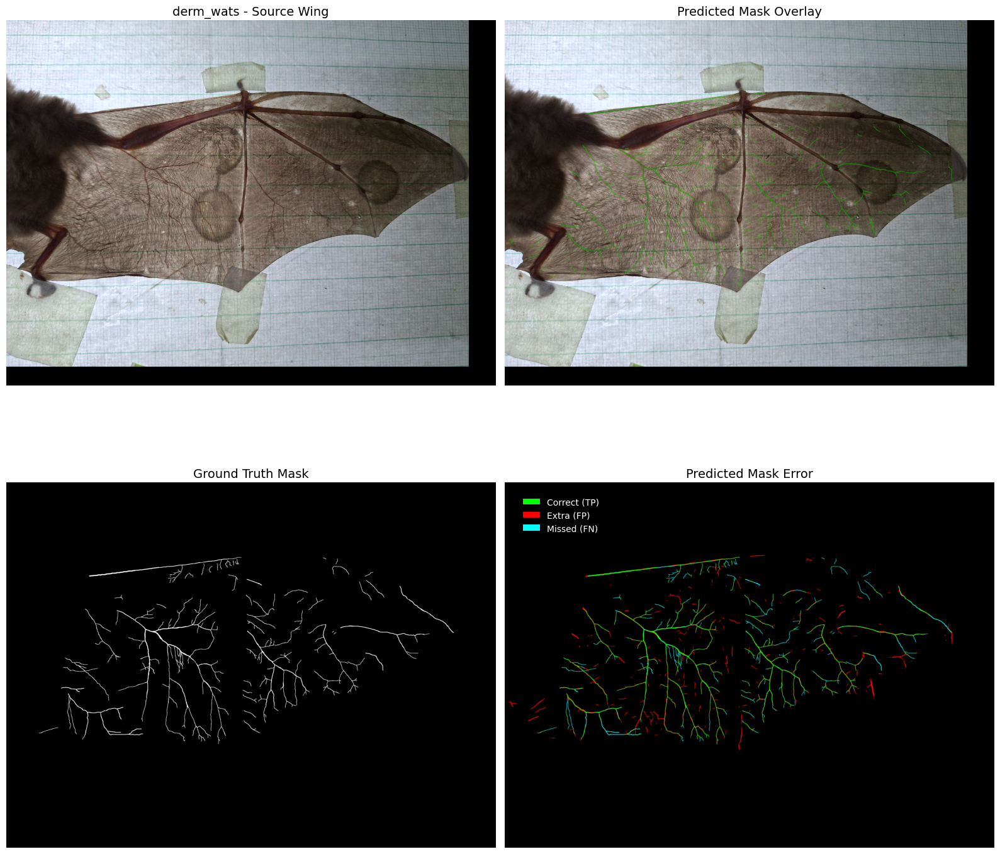

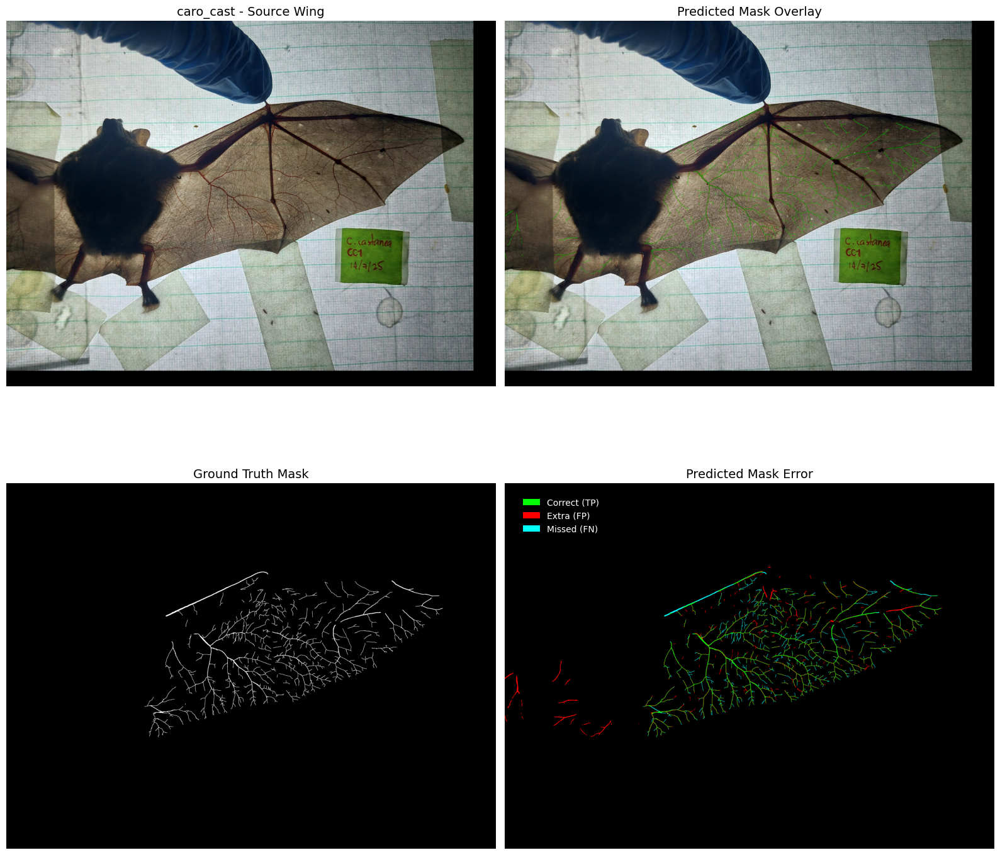

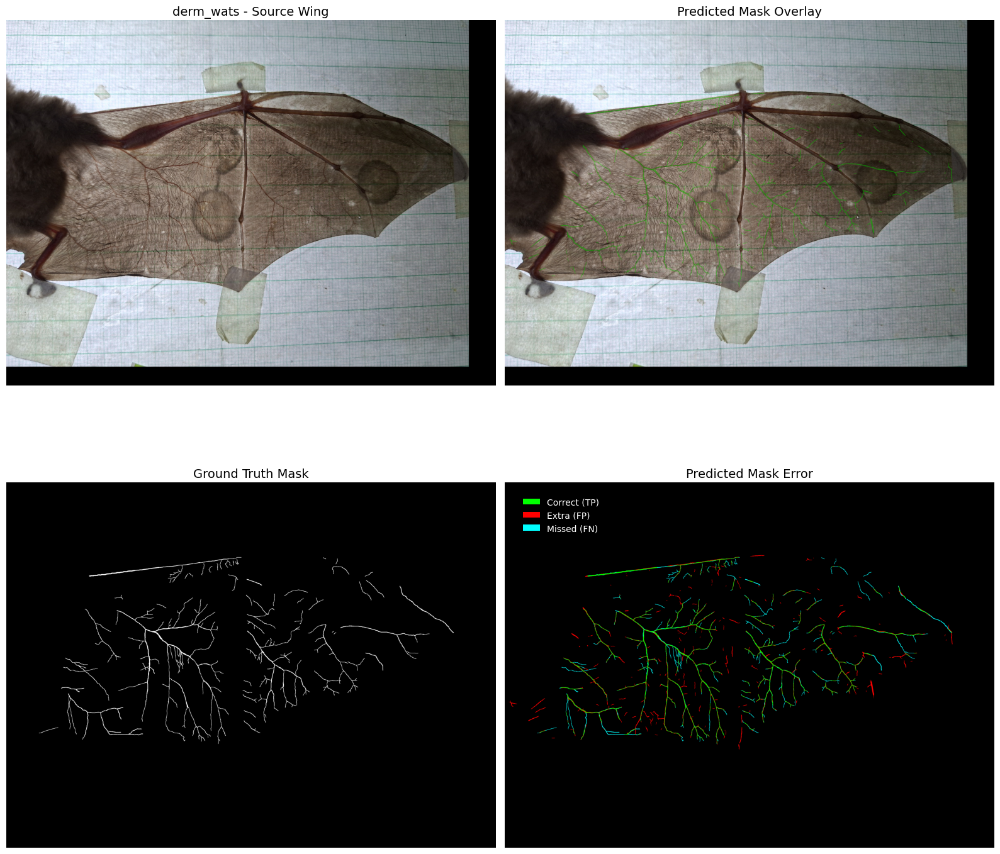

...

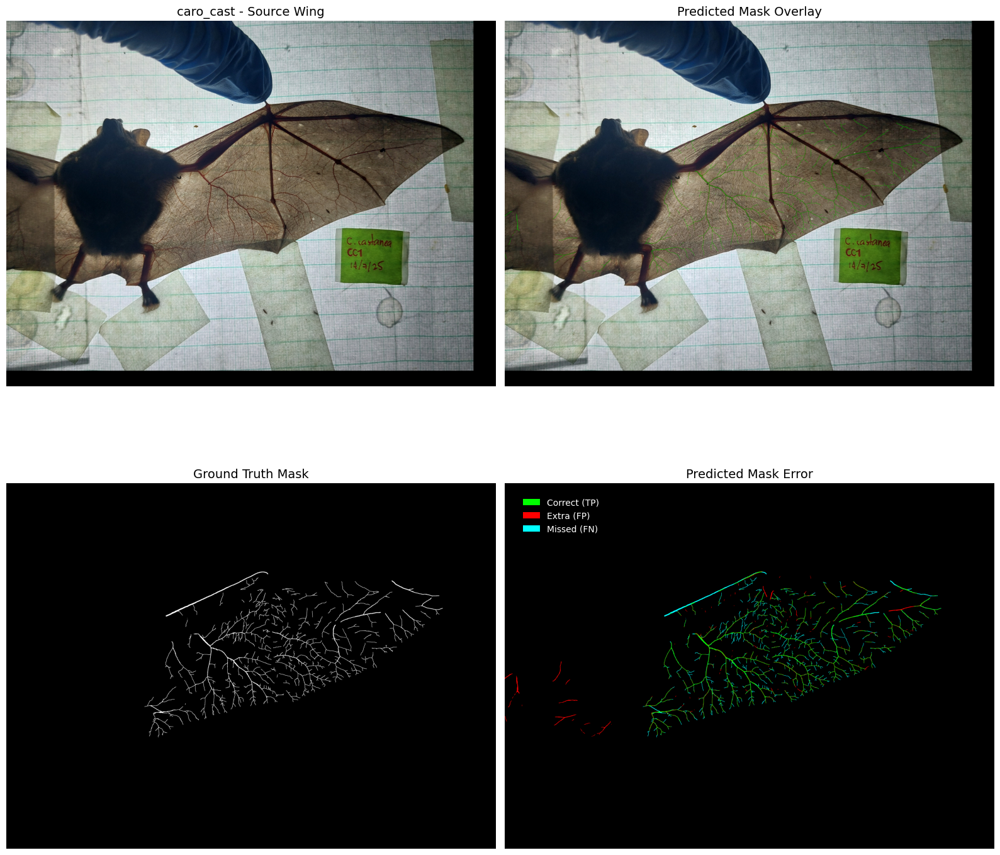

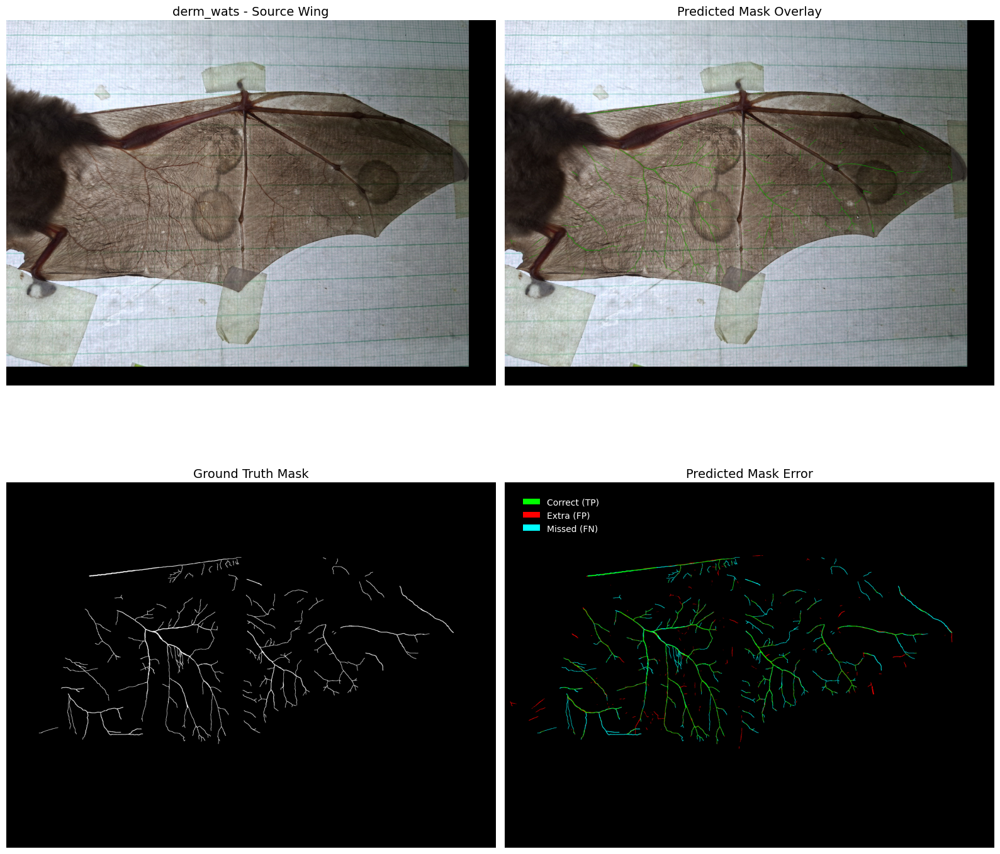

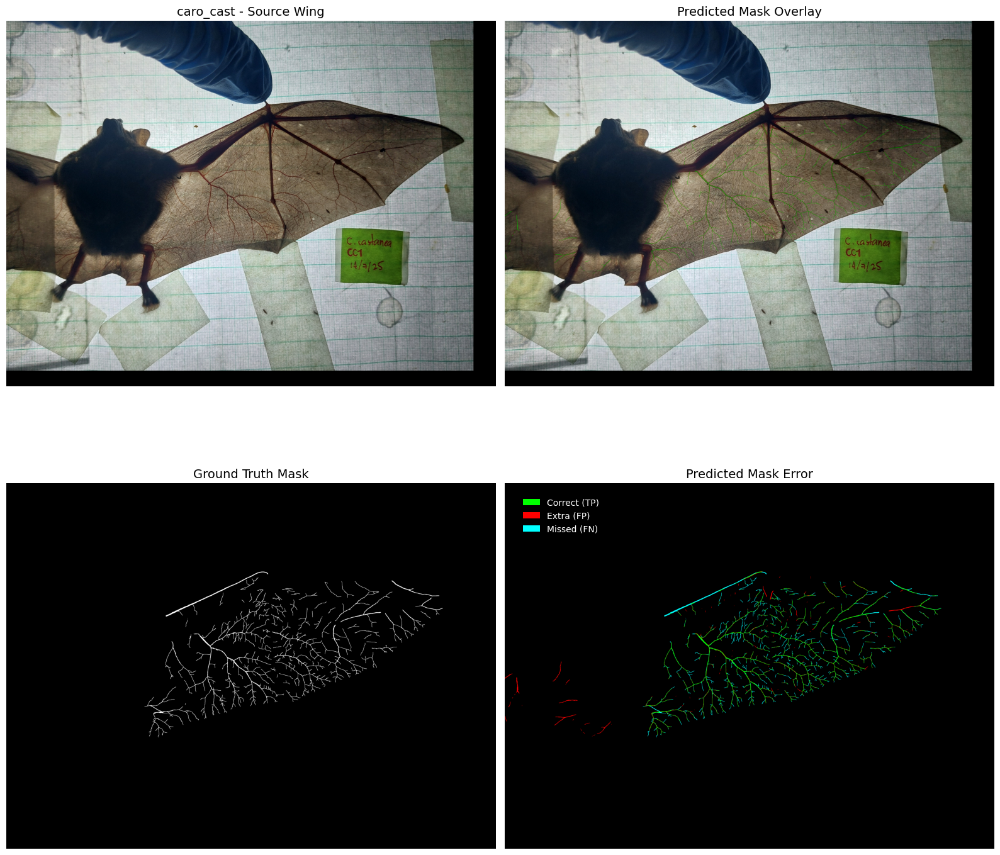

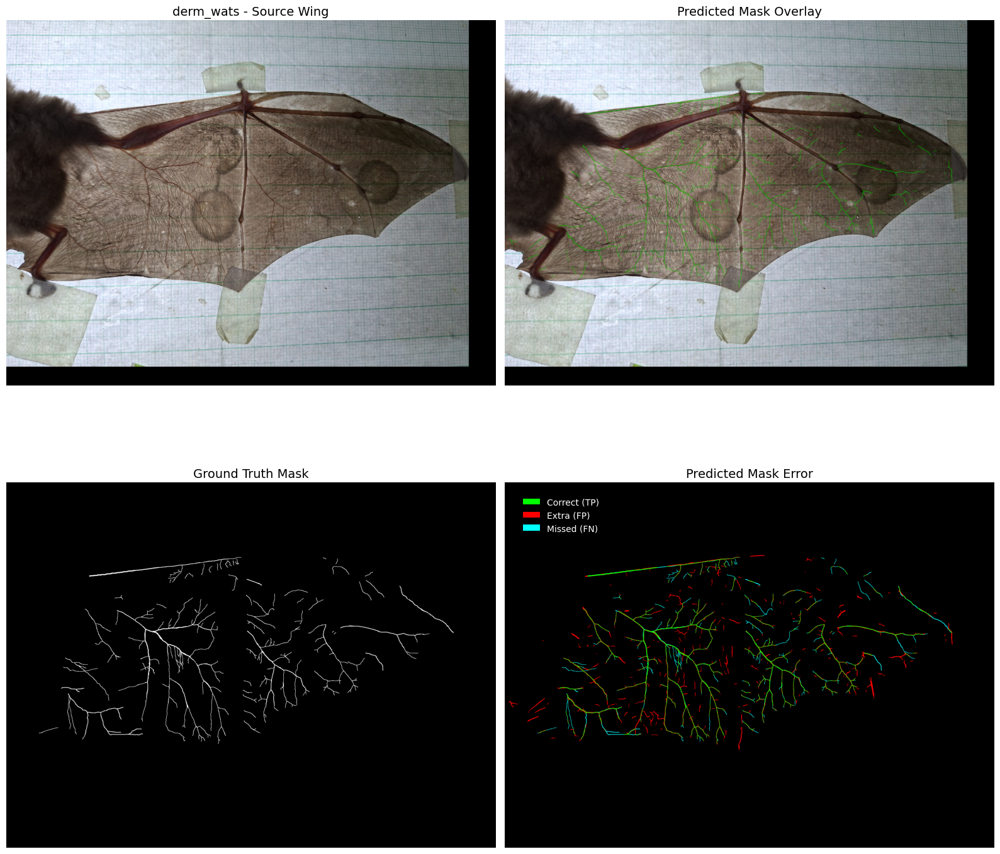

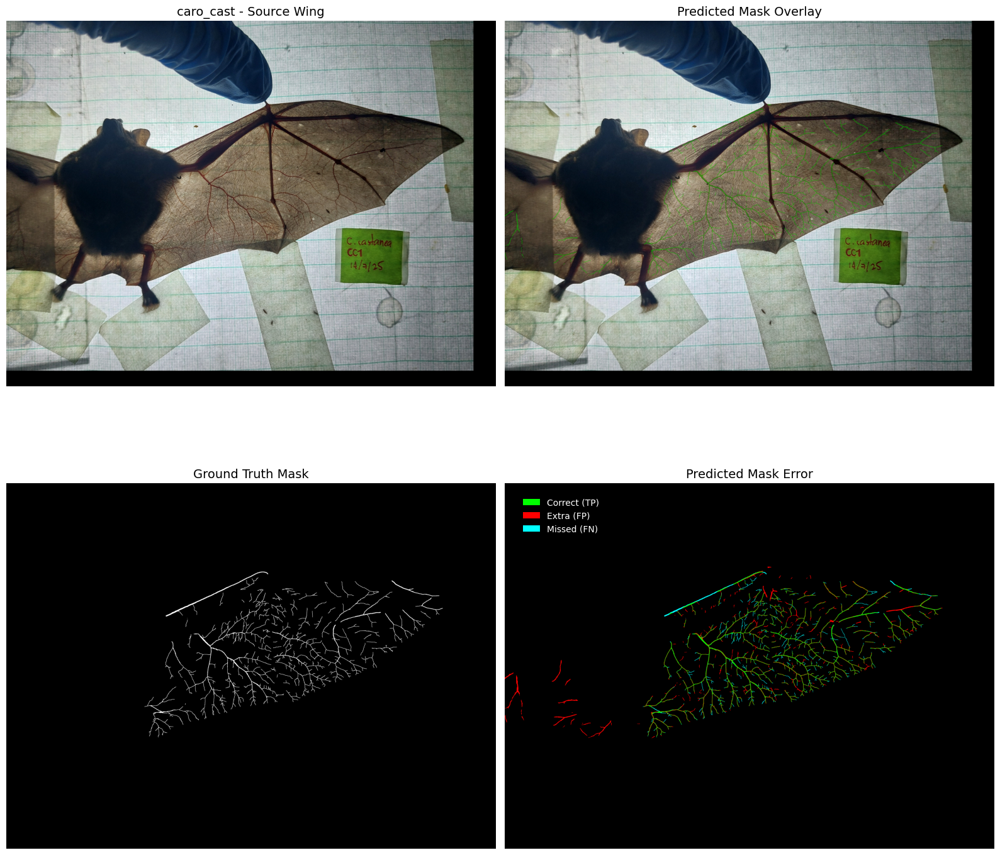

In [70]:
results = {(0.2, 0.6): [], (0.2, 0.7): [], (0.3, 0.7): [], (0.4, 0.8): [], (0.3, 0.8): [], (0.5, 0.8): [], (0.5, 0.9): [], (0.6, 0.9): [], (0.7, 0.9): [], (0.8, 0.9): [], (0.1, 0.5): []}

for threshold in [(0.2, 0.6), (0.2, 0.7), (0.3, 0.7), (0.4, 0.8), (0.3, 0.8), (0.5, 0.8), (0.5, 0.9), (0.6, 0.9), (0.7, 0.9), (0.8, 0.9), (0.1, 0.5)]:

    for source_id in val_df.source_id.unique():

        wing_source, wing_true, _, wing_pred_bin = stitch_predictions(
            val_set=val,
            source_id=source_id,
            prob_preds=prob_preds,
            overlap_pct=0.4,
            decision_threshold=0.5,
            gaussian_blending=True,
            hysteresis_thresholds=threshold
        )

        _, wing_metrics = evaluate_predicted_wing(
            source_id=source_id,
            wing_source=wing_source,
            wing_true=wing_true,
            wing_pred_bin=wing_pred_bin,
            show=False
        )
        results[threshold].append({"source_id": source_id, "wing_metrics": {"iou": f"{wing_metrics["wing_iou"]:.5f}", "precision": f"{wing_metrics["wing_precision"]:.5f}", "recall": f"{wing_metrics["wing_recall"]:.5f}"}})

In [ ]:
# hysteresis thresholds results with 2nd gen on full ds (derm_wats)
# baseline 0.41493
# (0.2, 0.7) 0.40777
# (0.3, 0.7) 0.41279
# (0.3, 0.8) 0.41386
# (0.4, 0.8) 0.41597
# (0.5, 0.8) 0.41587
# (0.1, 0.8) 0.39450
# (0.2, 0.6)

In [ ]:
wing_metrics # without

{'wing_iou': 0.41493646382749516,
 'wing_dice': 0.5865089697456309,
 'wing_precision': 0.5820777855598716,
 'wing_recall': 0.5910081380309289}

In [62]:
wing_metrics # with

{'wing_iou': 0.4158761124112252,
 'wing_dice': 0.5874470354655418,
 'wing_precision': 0.5871251943393268,
 'wing_recall': 0.5877692296246144}

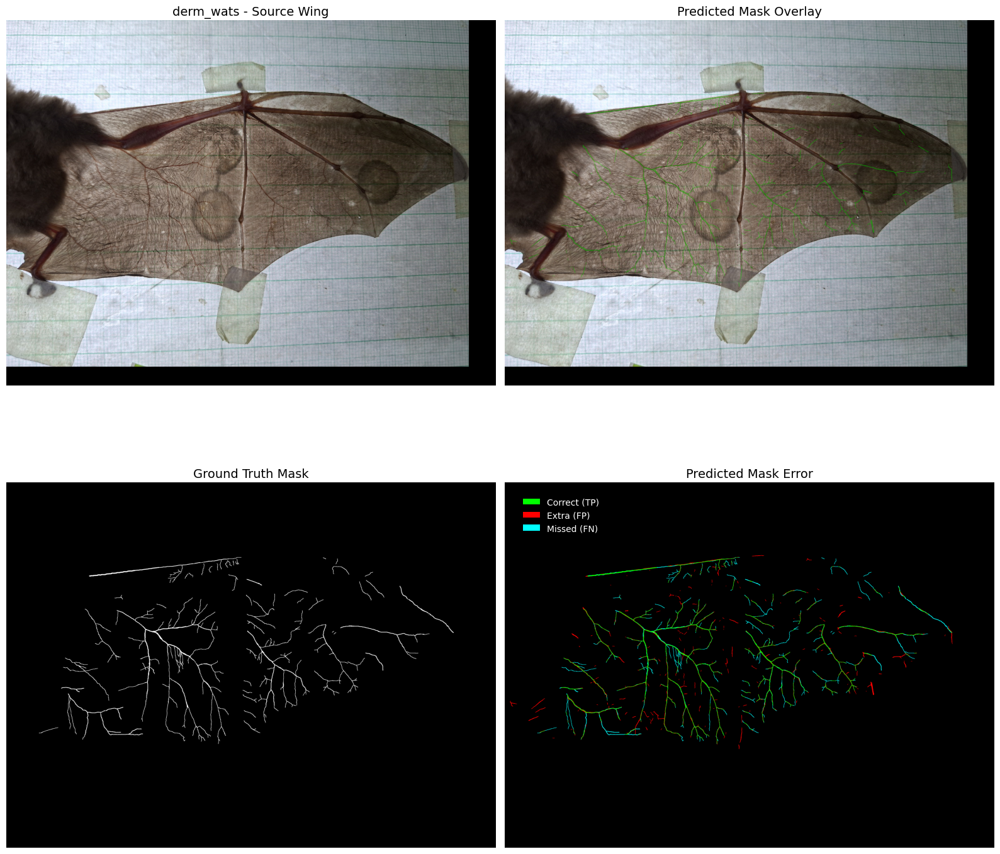

In [61]:
wing_fig, wing_metrics = evaluate_predicted_wing(
    source_id="derm_wats",
    wing_source=wing_source,
    wing_true=wing_true,
    wing_pred_bin=wing_pred_bin,
    show=True
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


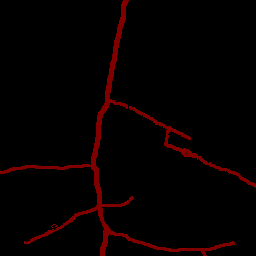

In [ ]:
Image.fromarray(val[300]["mask_color"])

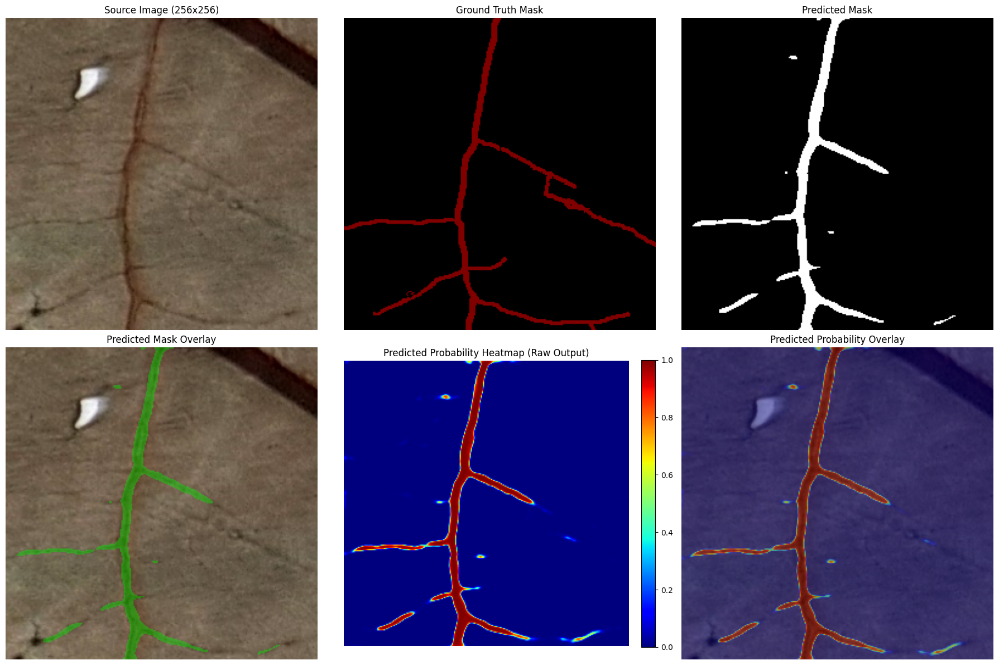

In [ ]:
model.eval()
with torch.no_grad():
    images = val[300]["image_tensor"].to(device).unsqueeze(0)
    masks = val[300]["mask_tensor"].to(device).float()
    logits = model(images)

    visualize_prediction(
        mask_pred = (torch.sigmoid(logits) > 0.5).float().squeeze().cpu(),
        prob_pred = torch.sigmoid(logits).squeeze().cpu(),
        val_set=val,
        id=val[300]["id"]
    )

In [ ]:
val[3]["measurements"]

{'coordinates_xy': '3,22',
 'length_mm': 0.0,
 'width_mm': 0.0,
 'area_mm2': 0.0,
 'species': 'lonc_conc',
 'source_id': 'lonc_conc',
 'val_fold': 2.0,
 'transforms_hash': '5c9cb5ae'}

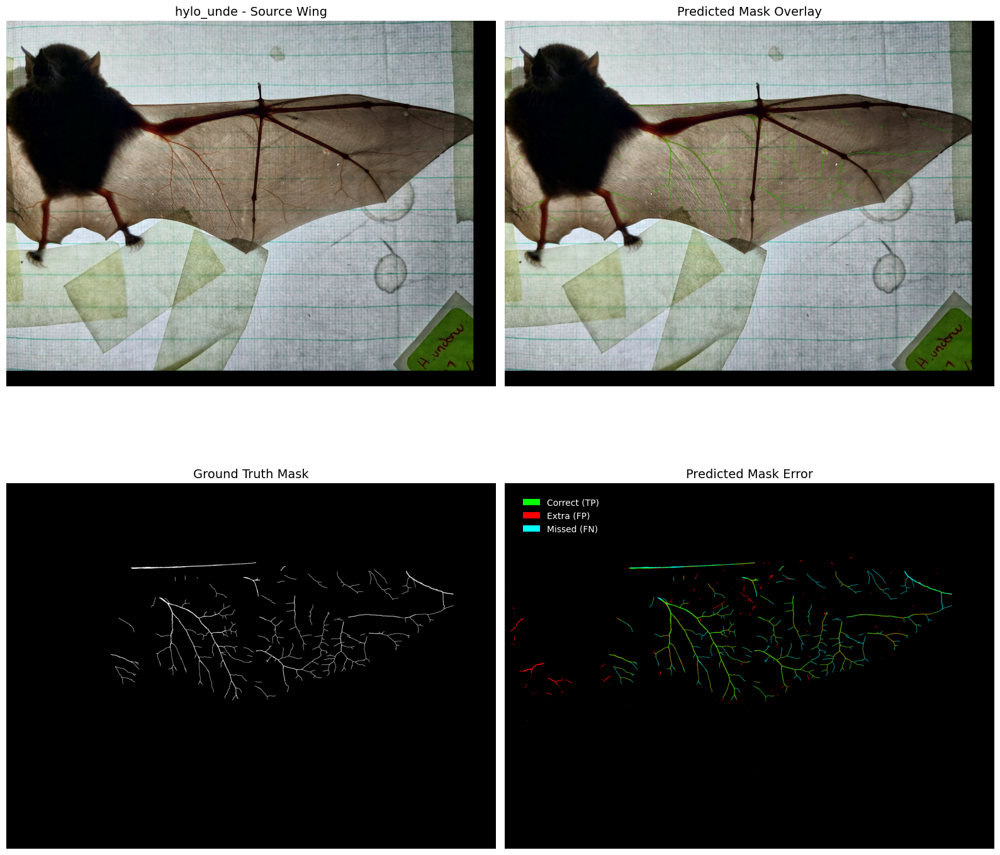

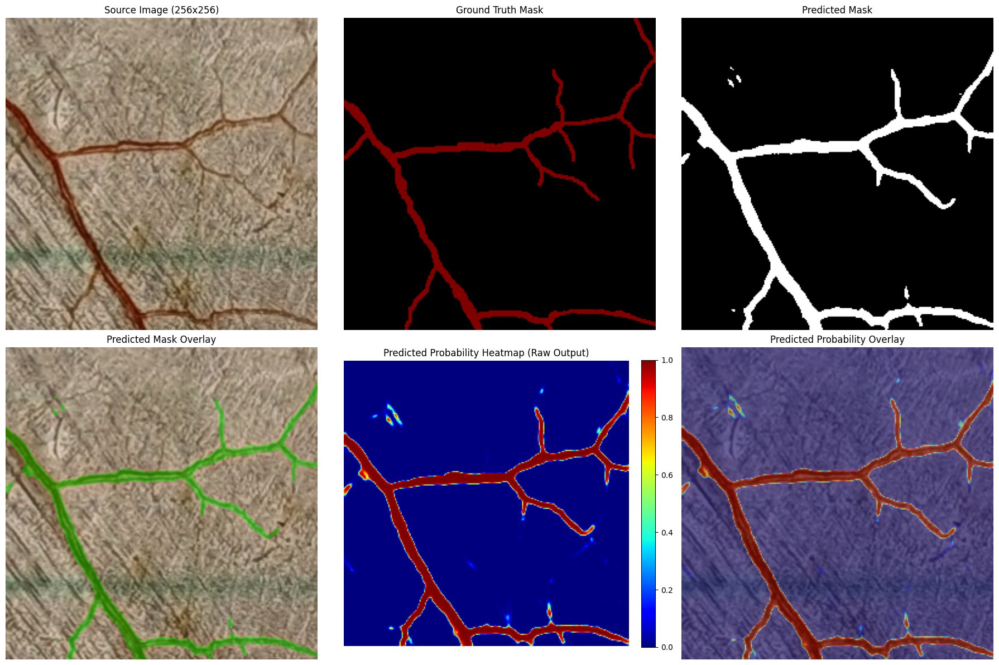

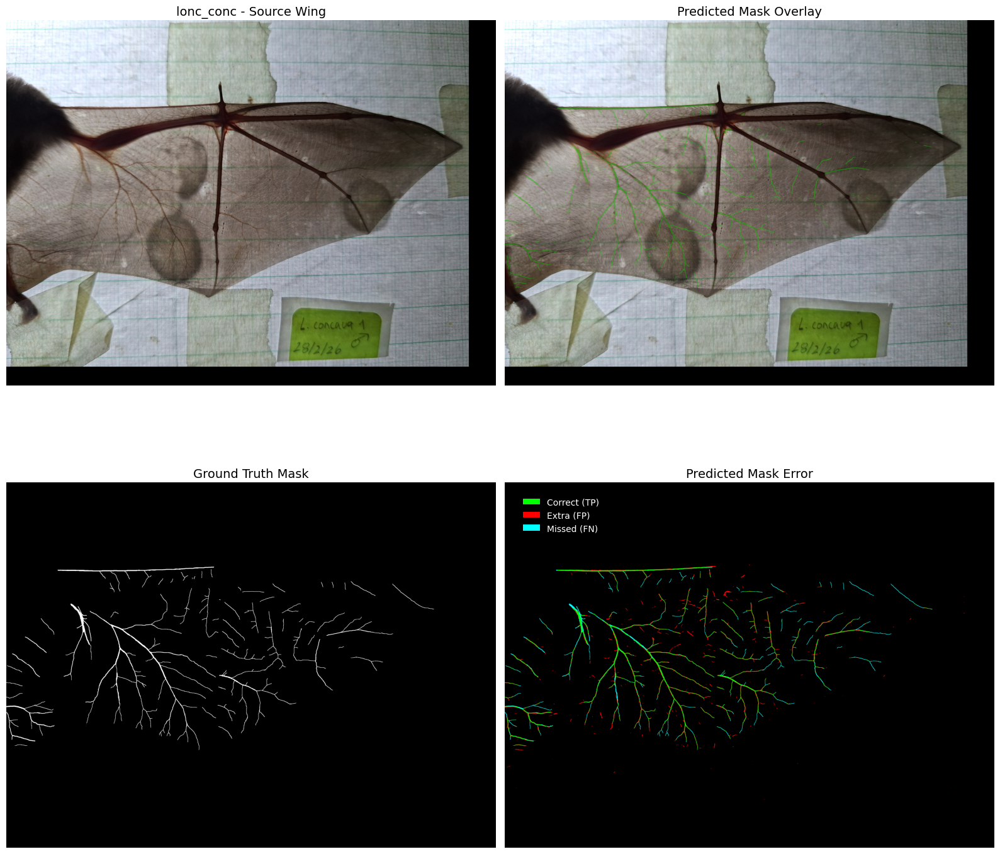

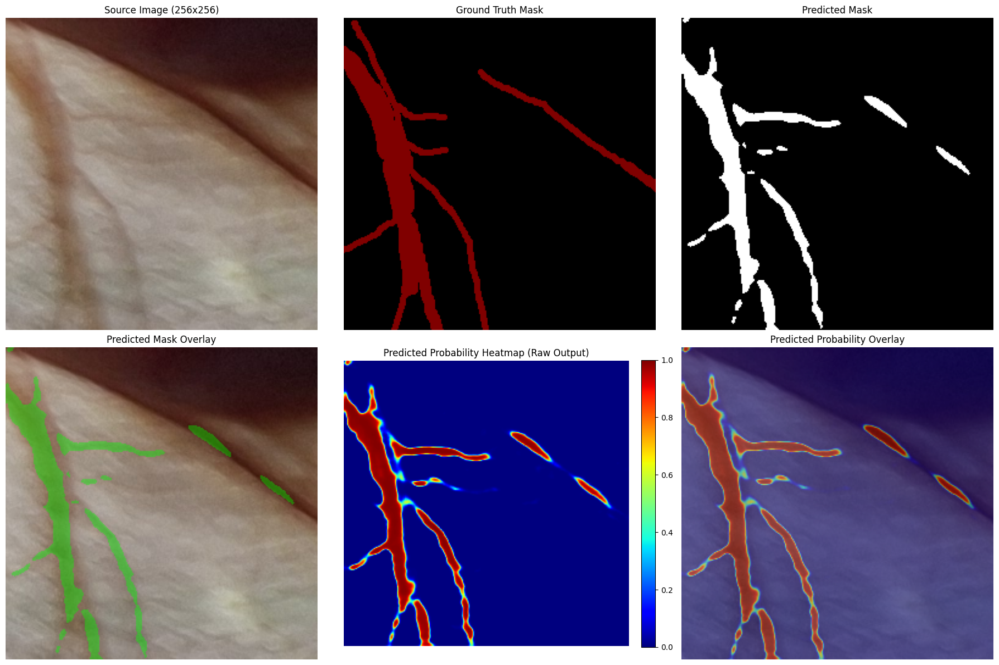

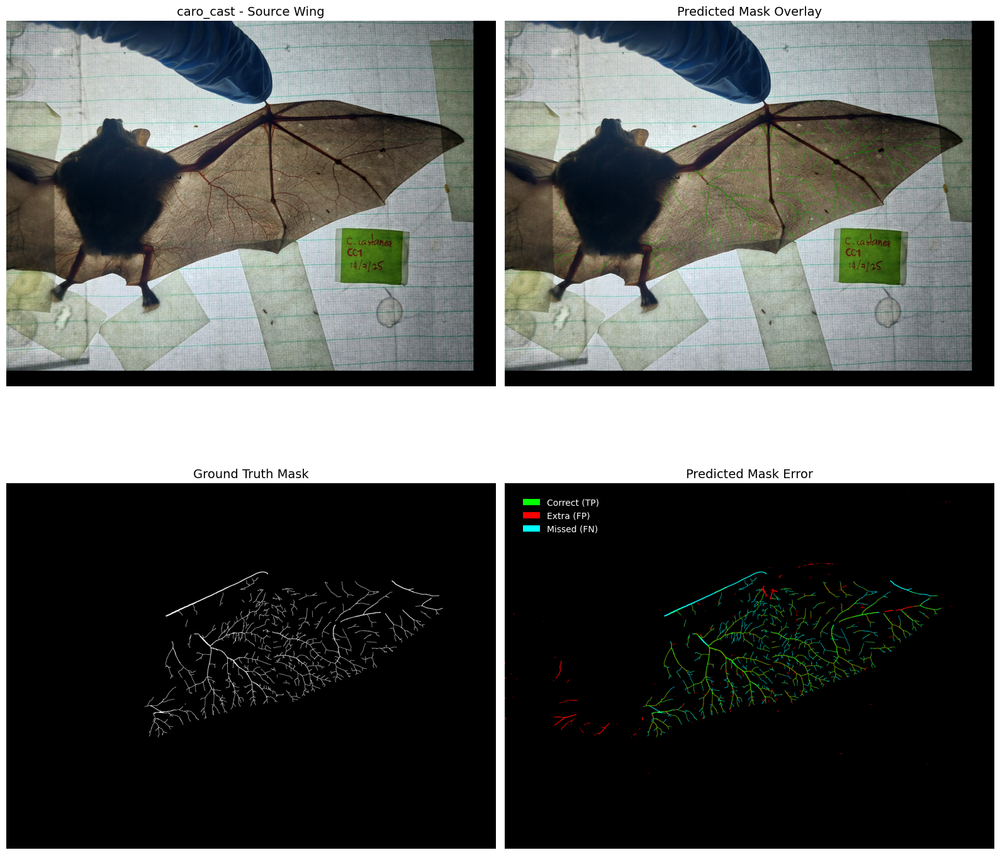

...

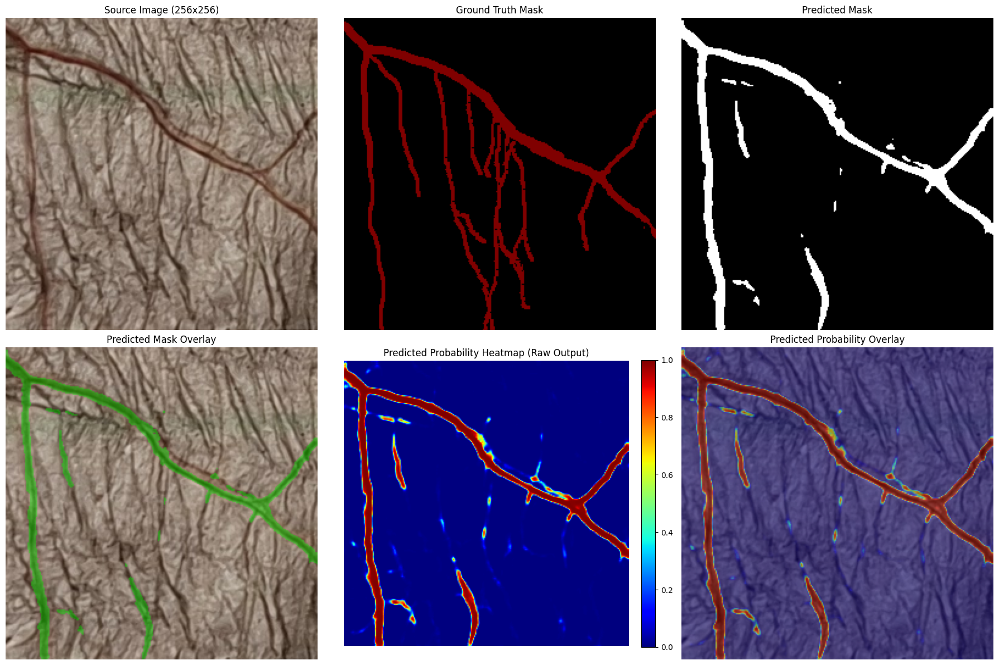

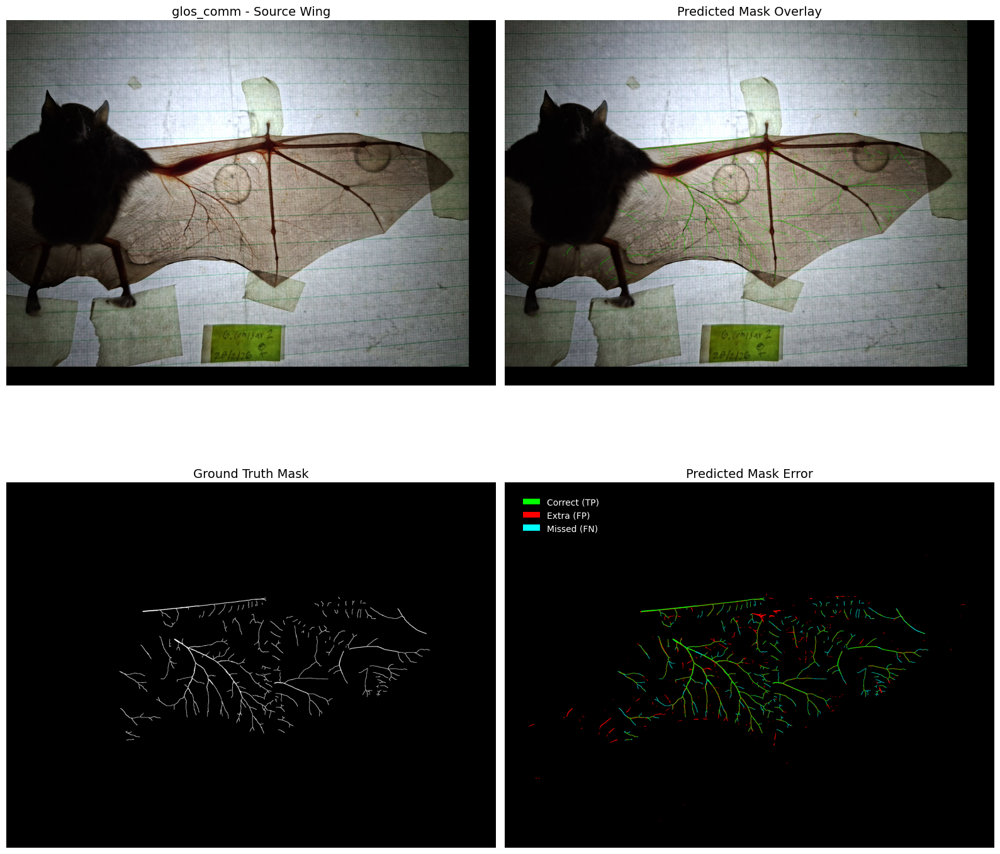

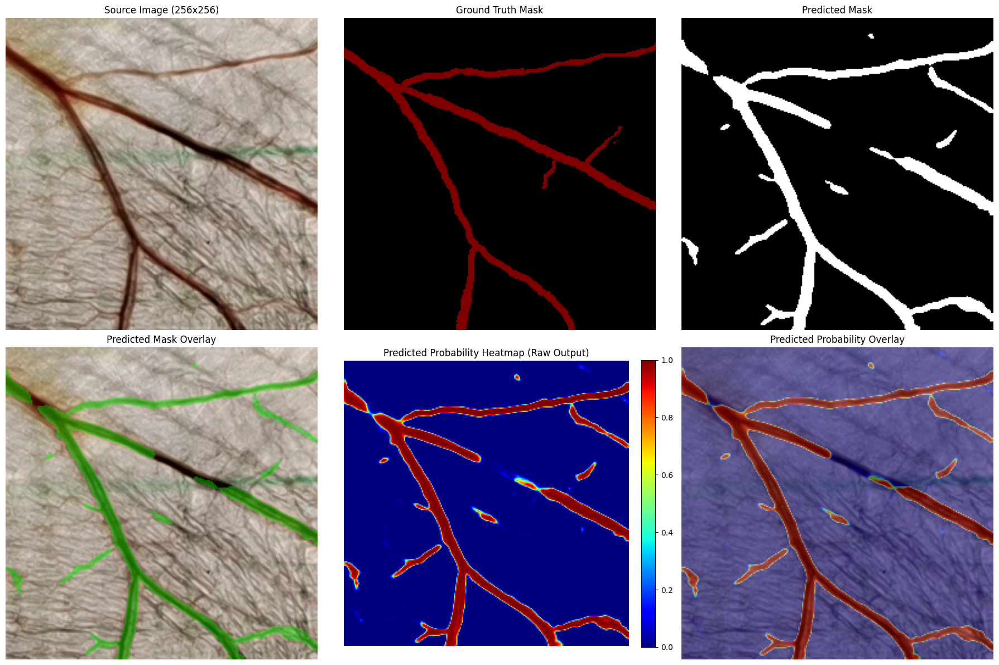

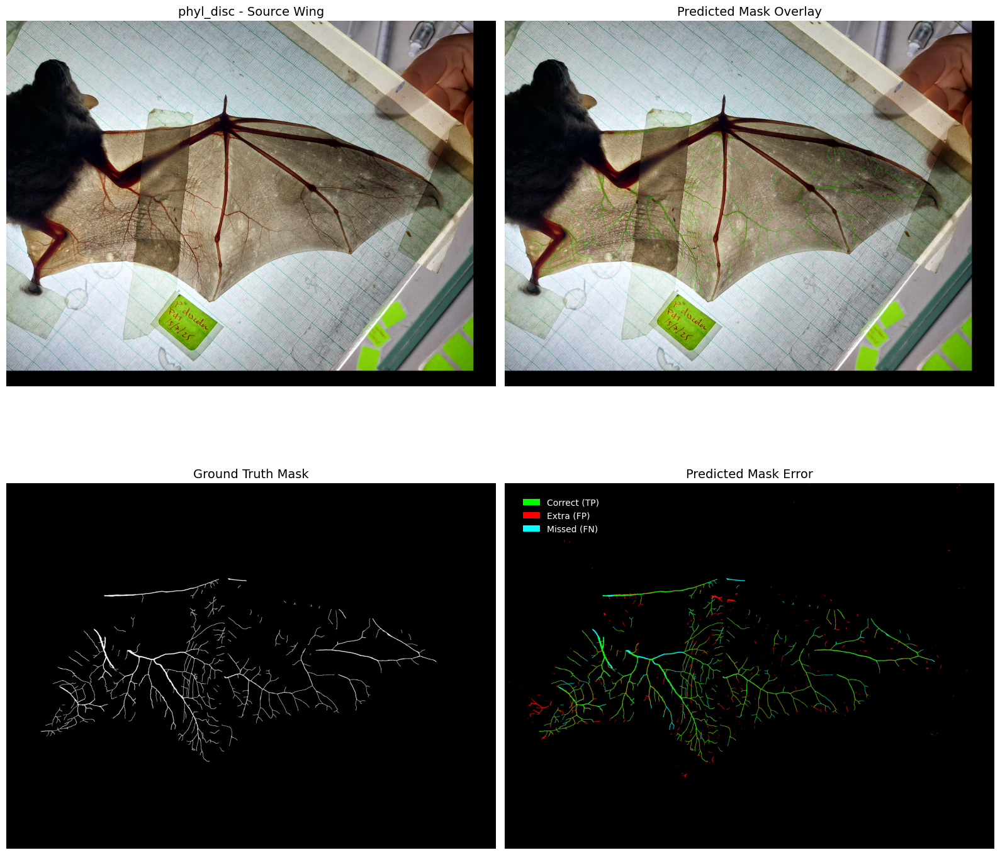

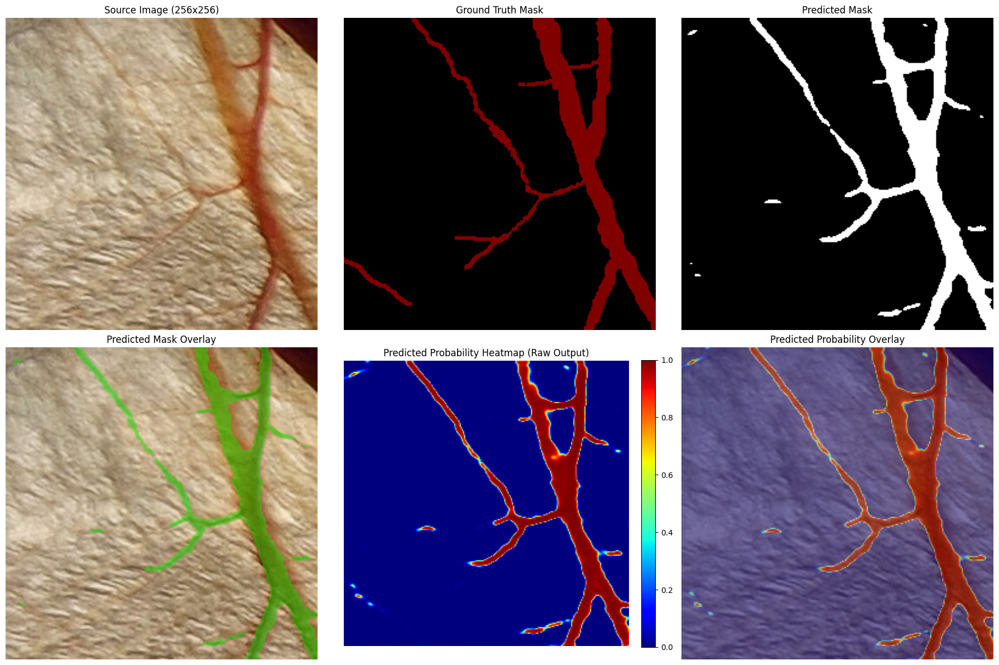

In [ ]:
model.eval()

df_list = []
mask_preds = []
probs_preds = []

with torch.no_grad():
    for batch in val_loader:

        images = batch["image_tensor"].to(device)
        masks = batch["mask_tensor"].to(device).float()
        logits = model(images)

        preds = (torch.sigmoid(logits) > 0.5).to(torch.uint8).squeeze(1).cpu()
        probs = torch.sigmoid(logits).squeeze().cpu()

        mask_preds.append(preds)
        probs_preds.append(probs)

        df_list.append(pd.DataFrame(batch["measurements"], index=batch["id"]))

mask_preds = torch.cat(mask_preds, dim=0)
probs_preds = torch.cat(probs_preds, dim=0)
val_df = pd.concat(df_list)

for source_id in val_df["source_id"].unique():

    # wing_fig = visualize_predicted_wing(
    #     val_set=val,
    #     source_id=source_id,
    #     mask_preds=mask_preds,
    #     show=True
    # )
    wing_fig = evaluate_predicted_wing(
        val_set=val,
        source_id=source_id,
        prob_preds=probs_preds,
        overlap_pct=0.4,
        decision_threshold=0.5,
        show=True
    )

    tile_id = val_df[val_df["source_id"] == source_id]["area_mm2"].idxmax()
    tile_idx = val_df.index.get_loc(tile_id)

    tile_fig = visualize_prediction(
        mask_pred=mask_preds[tile_idx],
        prob_pred=probs_preds[tile_idx],
        val_set=val,
        id=tile_id,
        show=True
    )


In [ ]:
val_df = pd.concat(df_list)

In [ ]:
val_df.index.value_counts().max()

1

In [ ]:
# Experimentation

# TODO: Try focal loss alone
# TODO: Write report for current experiments
# TODO: Test Self-Supervised Learning Weights
# TODO: Test new architectures for encoders & decoders (and attention mechanisms)
# TODO: Re-try some loss functions on best arch (if changed)
# TODO: Try postprocessing algorithms like Hysteresis Thresholding
# TODO: Write current state report
# TODO: Run sweep
# TODO: Test ensembling
# TODO: Evaluate final model on test set
# TODO: Write final report & paper methodology

# Codebase

# TODO: Test crossvalidate() refactor
# TODO: Revisit artifact download & base dirs
# TODO: implement wandb sweeps [...]
# TODO: write testing func

In [ ]:
def test():
    # Spin up wandb summary
    # Predict test set with ensmble of best weights from each fold
    # Log final metrics
    pass

In [ ]:
# TODO: Notebook organization, refactor and cleaning
# TODO: Tackle and plan model training loop

In [ ]:
# euclidean 1722 measured vs 1779 reported -3.20%
# complex 1907 measured vs 1779 reported +7.19%

In [ ]:
# img 44 with thick veins
# results, skeletonize + skan == 18
# results, skan == 140
# real == 13
# im 70 with a single straight vein
# results, skeletonize + skan == 7.63
# real == 7.59
# im 107 with thin veins
# results, skeletonize + skan == 20.53
# real == 16.6

# EDA

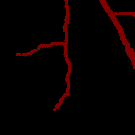

In [ ]:
Image.fromarray(train[404]["mask_color"])

/tmp/ipykernel_2337/1232036719.py:26: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=120, sigma=6.0, alpha_affine=3.6, p=0.8),


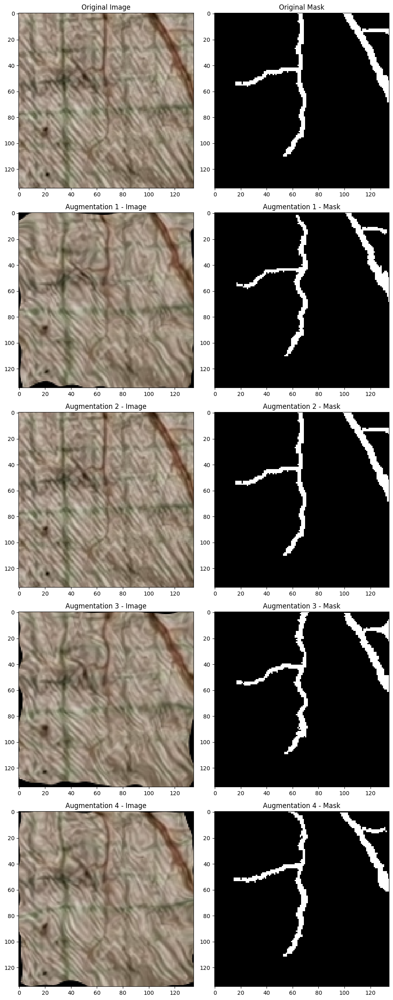

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

def visualize_augmentations(dataset, idx=404, num_samples=3):
    """
    Plots the original image/mask alongside multiple augmented versions.
    Assumes your dataset returns the raw numpy arrays BEFORE ToTensorV2 
    for easy plotting (or you can just pass raw images/masks directly).
    """
    # 1. Grab a raw image and mask from your disk (not the tensor)
    # Replace these paths with a real bat wing tile
    image = dataset[idx]["image"]
    mask = dataset[idx]["mask"]
    
    # 2. Define just the augmentations you want to test (no Normalization/ToTensor)
    test_transform = A.Compose([
        A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.5)
        A.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.2,
            hue=0.05,
            p=0.5
        ),
        A.ElasticTransform(alpha=120, sigma=6.0, alpha_affine=3.6, p=0.5)
    ])

    # 3. Setup the Matplotlib Grid
    fig, axes = plt.subplots(num_samples + 1, 2, figsize=(10, 5 * (num_samples + 1)))
    
    # Plot Original
    axes[0, 0].imshow(image)
    axes[0, 0].set_title("Original Image")
    axes[0, 1].imshow(mask, cmap="gray")
    axes[0, 1].set_title("Original Mask")
    
    # Generate and Plot Augmentations
    for i in range(1, num_samples + 1):
        augmented = test_transform(image=image, mask=mask)
        aug_img = augmented["image"]
        aug_mask = augmented["mask"]
        
        axes[i, 0].imshow(aug_img)
        axes[i, 0].set_title(f"Augmentation {i} - Image")
        axes[i, 1].imshow(aug_mask, cmap="gray")
        axes[i, 1].set_title(f"Augmentation {i} - Mask")
        
    plt.tight_layout()
    plt.show()

# Run the visualizer!
visualize_augmentations(train, num_samples=4)

Found 7 datasets to compare (VEINS ONLY).

Processing glos_comm (690 images)...


  0%|          | 0/690 [00:00<?, ?it/s]


Processing lonc_conc (690 images)...


  0%|          | 0/690 [00:00<?, ?it/s]


Processing caro_pers (884 images)...


  0%|          | 0/884 [00:00<?, ?it/s]

... (4 outputs left out)


Processing caro_cast (910 images)...


  0%|          | 0/910 [00:00<?, ?it/s]


EDA SUMMARY DATAFRAME (VEINS ONLY)


,RGB Mean,RGB Std,Duplicates,Empty Patches (%),Avg Vein Area (%)
Species,,,,,
glos_comm,"[136.0, 123.7, 110.2]","[48.8, 52.6, 54.0]",0,79.6%,3.80%
lonc_conc,"[113.4, 102.5, 94.3]","[40.1, 42.8, 44.1]",0,69.4%,3.56%
caro_pers,"[118.3, 107.7, 94.9]","[40.9, 43.0, 41.6]",0,61.0%,4.36%
derm_wats,"[112.8, 99.9, 88.8]","[42.5, 44.8, 47.6]",0,70.7%,3.66%
phyl_disc,"[136.2, 118.7, 96.8]","[50.6, 54.9, 51.9]",0,75.7%,4.56%
caro_cast,"[109.8, 98.2, 83.0]","[47.0, 50.1, 50.0]",0,80.9%,5.15%


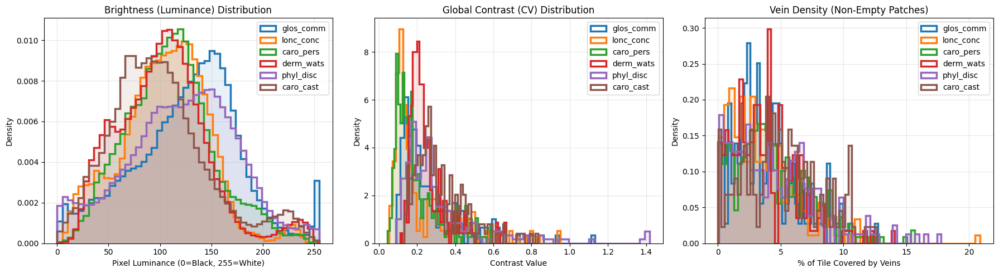

In [ ]:
import imagehash
import pybktree
from PIL import Image
from tqdm.notebook import tqdm

def compare_bat_datasets(concat_dataset, veins_only=False): # <-- ADDED TOGGLE
    # Temporarily turn off augmentations to get the pure raw images
    for ds in concat_dataset.datasets: 
        if hasattr(ds, 'train_mode'): ds.train_mode = False

    stats_list = []
    plot_data = {}

    mode_text = "(VEINS ONLY)" if veins_only else "(ALL TILES)"
    print(f"Found {len(concat_dataset.datasets)} datasets to compare {mode_text}.")

    for i, ds in enumerate(concat_dataset.datasets):
        # 1. Identify the dataset/species name
        if hasattr(ds, 'measurements') and len(ds.measurements) > 0:
            sample_source = ds.measurements["source_id"].iloc[0]
            subset_name = "_".join(sample_source.split("_")[:2]) 
        else:
            subset_name = f"Dataset_{i}"

        # # Filtering logic
        # if subset_name not in ["phyl_disc", "caro_pers", "lonc_conc"]:
        #     continue
            
        if len(ds) == 0:
            print(f"\nSkipping {subset_name} (0 images)...")
            continue
            
        print(f"\nProcessing {subset_name} ({len(ds)} images)...")

        # 2. Extract Data for this specific dataset
        images, masks = [], []
        for idx in tqdm(range(len(ds)), leave=False):
            sample = ds[idx]
            images.append(sample["image"])
            mask_arr = sample.get("mask_color", sample.get("mask"))
            masks.append(mask_arr)

        images = np.stack(images, axis=0)
        masks = np.stack(masks, axis=0)
        
        if masks.ndim == 4: masks = masks[..., 0] 
        masks = (masks > 0).astype(np.uint8) 

        # 3. Calculate Coverage FIRST
        coverage_per_mask = masks.reshape(masks.shape[0], -1).mean(axis=1)
        has_veins = coverage_per_mask > 0
        active_coverage = coverage_per_mask[has_veins] * 100 
        empty_mask_pct = (~has_veins).mean() * 100
        
        original_count = len(images)

        # --- APPLY THE TOGGLE ---
        if veins_only:
            images = images[has_veins]
            masks = masks[has_veins]
            if len(images) == 0:
                print(f"Skipping {subset_name} (0 patches with veins)...")
                continue

        # 4. Calculate RGB & Luminance Stats (Now uses filtered images if toggled)
        rgb_mean = images.reshape(-1, 3).mean(0)
        rgb_std = images.reshape(-1, 3).std(0)
        
        luma_per_px = np.dot(images, [0.299, 0.587, 0.114])
        lumas_per_img = luma_per_px.reshape(luma_per_px.shape[0], -1)
        norm_contrast = lumas_per_img.std(axis=1) / (lumas_per_img.mean(axis=1) + 1e-8)

        # 5. Near-Duplicate Hashing (Now operates only on filtered images)
        hashes = [int(str(imagehash.phash(Image.fromarray(img))), 16) for img in images]
        items = [(h, idx) for idx, h in enumerate(hashes)]
        tree = pybktree.BKTree(lambda a, b: (a[0] ^ b[0]).bit_count(), items)
        
        marked_duplicates = set()
        for h_i, idx in items:
            for dist, (h_j, jdx) in tree.find((h_i, idx), 10):
                if jdx != idx:
                    marked_duplicates.add(idx)
                    marked_duplicates.add(jdx)
                    break

        # Store Scalar Stats
        stats_list.append({
            "Species": subset_name,
            #"Total Tiles": original_count,
            #"Analyzed Tiles": len(images), # Shows the drop if veins_only=True
            "RGB Mean": f"[{rgb_mean[0]:.1f}, {rgb_mean[1]:.1f}, {rgb_mean[2]:.1f}]",
            "RGB Std": f"[{rgb_std[0]:.1f}, {rgb_std[1]:.1f}, {rgb_std[2]:.1f}]",
            "Duplicates": len(marked_duplicates),
            "Empty Patches (%)": f"{empty_mask_pct:.1f}%",
            "Avg Vein Area (%)": f"{active_coverage.mean():.2f}%" if len(active_coverage) > 0 else "0%"
        })

        plot_data[subset_name] = {
            "luma": luma_per_px.ravel(),
            "contrast": np.clip(norm_contrast, None, np.percentile(norm_contrast, 99.5)),
            "coverage": active_coverage # active_coverage naturally excludes empty patches already
        }

    # ==========================================
    # VISUALIZATIONS
    # ==========================================
    if not stats_list:
        print("No valid datasets found to process!")
        return
        
    print("\n" + "="*50)
    print(f"EDA SUMMARY DATAFRAME {mode_text}")
    print("="*50)
    df_summary = pd.DataFrame(stats_list).set_index("Species")
    display(df_summary)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    colors = plt.cm.tab10.colors 
    
    for i, (species, data) in enumerate(plot_data.items()):
        c = colors[i % len(colors)]
        
        axes[0].hist(data["luma"], bins=50, density=True, histtype="step", linewidth=2.5, label=species, color=c)
        axes[0].hist(data["luma"], bins=50, density=True, histtype="stepfilled", alpha=0.1, color=c)
        
        axes[1].hist(data["contrast"], bins=50, density=True, histtype="step", linewidth=2.5, label=species, color=c)
        axes[1].hist(data["contrast"], bins=50, density=True, histtype="stepfilled", alpha=0.1, color=c)
        
        axes[2].hist(data["coverage"], bins=50, density=True, histtype="step", linewidth=2.5, label=species, color=c)
        axes[2].hist(data["coverage"], bins=50, density=True, histtype="stepfilled", alpha=0.1, color=c)

    axes[0].set_title("Brightness (Luminance) Distribution", fontsize=12)
    axes[0].set_xlabel("Pixel Luminance (0=Black, 255=White)")
    
    axes[1].set_title("Global Contrast (CV) Distribution", fontsize=12)
    axes[1].set_xlabel("Contrast Value")
    
    axes[2].set_title("Vein Density (Non-Empty Patches)", fontsize=12)
    axes[2].set_xlabel("% of Tile Covered by Veins")

    for ax in axes:
        ax.legend(loc="upper right")
        ax.grid(alpha=0.3)
        ax.set_ylabel("Density")

    plt.tight_layout()
    plt.show()

# --- HOW TO RUN IT ---
# Pass True to analyze only patches containing veins!
compare_bat_datasets(train, veins_only=True)

In [ ]:
images, masks = [], []
for idx in range(len(dataset)):
  images.append(dataset[idx]["image"])
  masks.append(dataset[idx]["mask"])

try:
    images = np.stack(images, axis=0)
    masks = np.stack(masks, axis=0)
    print(f"Dataset shape: {images.shape}")
except ValueError as e:
    print("Irregular image sizes")

Dataset shape: (496, 135, 135, 3)


In [ ]:
print(f"RGB channel-wise mean {images.reshape(-1,3).mean(0)}")
print(f"RGB channel-wise std {images.reshape(-1,3).std(0)}")

RGN channel-wise mean [141.22439765 134.97770831 121.35913569]
RGN channel-wise std [62.03206385 68.3298709  71.24540857]


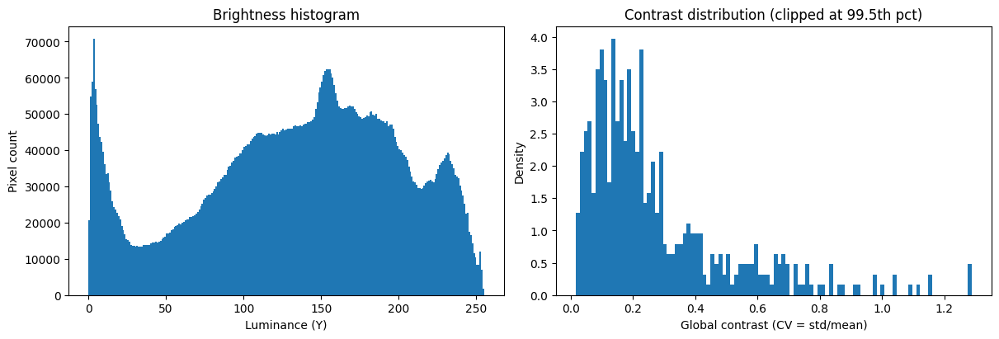

In [ ]:
# @title luminance statistics

import matplotlib.pyplot as plt

luma_per_px = np.dot(images, [0.299, 0.587, 0.114]) # array[...,:3] == array[:, :, :, etc, :3]
lumas_per_img = luma_per_px.reshape(luma_per_px.shape[0], -1)
norm_contrast_per_img = lumas_per_img.std(axis=1) / (lumas_per_img.mean(axis=1) + 1e-8)

edges = np.linspace(0.0, 255.0, 256)
counts, _ = np.histogram(luma_per_px.ravel(), bins=edges)
centers = 0.5 * (edges[1:] + edges[:-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].bar(centers, counts, width=np.diff(edges), align="center")
axes[0].set_xlabel("Luminance (Y)")
axes[0].set_ylabel("Pixel count")
axes[0].set_title("Brightness histogram")

clipped = np.clip(norm_contrast_per_img, None, np.percentile(norm_contrast_per_img, 99.5))
axes[1].hist(clipped, bins=100, density=True)
axes[1].set_xlabel("Global contrast (CV = std/mean)")
axes[1].set_ylabel("Density")
axes[1].set_title("Contrast distribution (clipped at 99.5th pct)")

plt.show()

In [ ]:
# sizing check [DONE]
# Benchmark feasibility [LATER]
# Per-channel mean/std; brightness/contrast histograms; white balance drift across sources. [DONE]
# Perceptual hash (pHash/aHash/dHash) to collapse near-identical images; remove leakage across splits [DONE]
# mask coverage % [DONE]

In [ ]:
import imagehash
from pybktree import BKTree
hashes = []
for img in images:
  hash = imagehash.phash(Image.fromarray(img))
  hashes.append(int(str(hash), 16))
items = [(int(h), i) for i, h in enumerate(hashes)]
tree = BKTree(lambda a, b: (a[0] ^ b[0]).bit_count(), items)
marked = set()
for h_i, i in items:
    for dist, (h_j, j) in tree.find((h_i, i), 10):
        if j != i: marked.add(i) ; marked.add(j) ; break
sorted(marked)

In [ ]:
import numpy as np, cv2, pandas as pd, glob

def coverage(mask_path, pos_id=1):
    m = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    if m.ndim==3: m = m[...,0]
    # binarize robustly
    m = (m==pos_id) if m.max()<=1 else (m>0)
    return float(m.mean())

msk_paths = sorted(glob.glob("data/mask/**/*.png", recursive=True))
cov = [coverage(p) for p in msk_paths]
import numpy as np
print(np.mean(cov), np.median(cov), np.percentile(cov, [0,1,5,95,99,100]))

In [ ]:
coverage_per_mask = masks.reshape(masks.shape[0], -1).mean(axis=1)

In [ ]:
np.where(coverage_per_mask>0, 1, 0).mean()

np.float64(0.36363636363636365)

In [ ]:
masks = np.stack(masks, axis=0)

In [ ]:
pd.Series(coverage_per_mask[np.where(coverage_per_mask>0, 1, 0).astype(bool)]).describe()

,0
count,300.000000
mean,0.052724
std,0.031987
min,0.004444
25%,0.028903
50%,0.048176
75%,0.070878
max,0.171248


<Axes: >

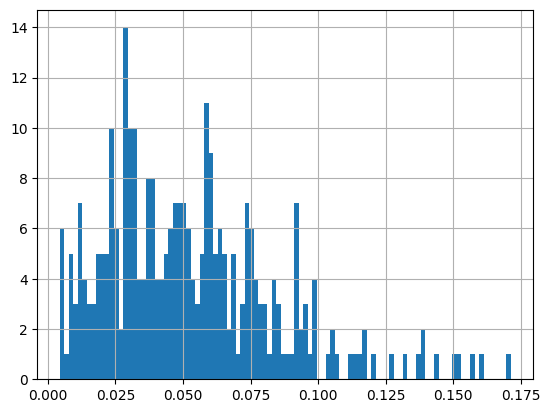

In [ ]:
pd.Series(coverage_per_mask[np.where(coverage_per_mask>0, 1, 0).astype(bool)]).hist(bins=100)

In [ ]:
# Hash size 8 (default 64-bit pHash/dHash/aHash):

# ≤ 5 → essentially identical

# ≤ 8–10 → near-duplicate (same photo, tiny edits/rescale/brightness)

# > 10 → likely different

# Training

In [ ]:
# version:

# Augmentation transformers arch
# 	metadata: family, encoder, pretraining ds, input resolution

# Augmentation pipelines arch
# 	metadata: n steps, difficulty, resizing?, geometry?, color?, output/input resolution & channels

# Model weights

# Model arch
# 	metadata: family, encoder, pretraining ds, input resolution

In [ ]:
import segmentation_models_pytorch as smp

def get_model(config, model_ref=None):

    if model_ref:
        _, model_path = download_artifact(model_ref)
        model = smp.Unet.load_from_checkpoint(model_path)
        return model

    params = config.copy()
    arch_name = params.pop("arch")
    model_class = getattr(smp, arch_name)
    model = model_class(**params)
    
    return model

In [ ]:
def get_model():
    pass

In [ ]:
def train_epoch():
    pass

# Validation

In [ ]:
def evaluate():
    pass

In [ ]:
def cross_validate():
    pass

# Postprocessing

In [ ]:
from skimage.morphology import skeletonize, remove_small_holes
from scipy.ndimage import distance_transform_edt
from skan import Skeleton, summarize
import numpy as np

def estimate_vein_stats(mask: np.ndarray, px_mm_ratio:float):

    mask = remove_small_holes(mask.astype(bool), area_threshold=3)
    skeleton = skeletonize(mask)
    
    if np.sum(skeleton) == 0: 
        return {
            "mm_length": 0.0, "px_length": 0.0, "px_correction": 0.0, 
            "junction_count": 0, "percent_reduction": 0.0, 
            "avg_px_width": 0.0, "avg_mm_width": 0.0,
            "area_px": 0, "area_mm2": 0.0
        }

    radius_map = distance_transform_edt(mask)
    
    skeleton_radii = radius_map[skeleton]
    avg_px_width = 2.0 * np.mean(skeleton_radii)
    avg_mm_width = avg_px_width * px_mm_ratio
    
    area_px = np.sum(mask)
    area_mm2 = area_px * (px_mm_ratio ** 2)
    
    skel_obj = Skeleton(skeleton)
    branch_df = summarize(skel_obj, separator="-")
    
    total_px_length = branch_df["branch-distance"].sum()
    junction_indices = np.where(skel_obj.degrees > 2)[0]
    total_px_correction = 0.0
    
    for node_idx in junction_indices:

        y, x = skel_obj.coordinates[node_idx].astype(int)
        radius = radius_map[y, x]
        degree = skel_obj.degrees[node_idx]
        correction = (degree - 2) * radius
        total_px_correction += correction

    corrected_px_length = max(0, total_px_length - total_px_correction)
    total_mm_length = corrected_px_length * px_mm_ratio
    
    return {
        "mm_length": total_mm_length,
        "px_length": total_px_length,
        "px_correction": total_px_correction,
        "junction_count": len(junction_indices),
        "percent_reduction": (total_px_correction / total_px_length) * 100,
        "px_avg_width": float(avg_px_width),
        "mm_avg_width": float(avg_mm_width),
        "px_area": int(area_px),
        "mm2_area": float(area_mm2)
    }

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import Circle

def visualize_highway_correction(mask: np.ndarray):

    skeleton = skeletonize(mask)
    radius_map = distance_transform_edt(mask)
    skel_obj = Skeleton(skeleton)
    junction_indices = np.where(skel_obj.degrees > 2)[0]

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(mask, cmap="gray_r", alpha=0.3)
    y_skel, x_skel = np.where(skeleton)
    ax.scatter(x_skel, y_skel, c="red", s=2, label="Skeleton")
    
    for node_idx in junction_indices:
        y, x = skel_obj.coordinates[node_idx]
        r = radius_map[int(y), int(x)]
        circ = Circle((x, y), r, color="blue", fill=False, linewidth=1.5)
        ax.add_patch(circ)

    ax.set_title("Blue Circles = Junction Areas (Subtracted Regions)")
    ax.legend()
    plt.show()

In [ ]:
def generate_measurements(mask_dir):
    # parse coords from name
    # calculate length mm, area mm2 and avg width mm
    pass

In [ ]:
total_lengths_mm = []
for idx in range(len(dataset)):
    mask = dataset[idx]["mask"]
    length_mm, _ = highway_corrected_centerline_length(mask, px_mm_ratio=0.0563)
    total_lengths_mm.append(length_mm)
print(f"Total Vessel Length across Dataset: {sum(total_lengths_mm):.2f} mm")
print(f"Dataset Reported Total Vessel Length: {dataset.df['length_mm'].sum():.2f} mm")

Total Vessel Length across Dataset: 1907.70 mm
Dataset Reported Total Vessel Length: 1779.66 mm
